# London Residential Property Market — Exploratory Data Analysis

**Scope:** 54,882 standard-market residential sales in London postal districts (E, EC, N, NW, SE, SW, W, WC), completed January 2025 – January 2026.

**Sources:** HM Land Registry Price Paid Data · postcodes.io (ONS postcode geography) · data.police.uk street-level crime (Metropolitan Police and City of London Police).

**Purpose:** understand the drivers of residential prices before building an automated valuation model (AVM), and identify data issues and modelling decisions that the evidence supports. Part I (Sections 1–8) profiles the data one variable at a time; Part II (Sections 9–16) applies the methods a valuation or model-risk team would use: hedonic regression, mix-adjusted indexing, spatial diagnostics and a comparable-sales baseline.

*Contains HM Land Registry data © Crown copyright and database right 2026. This data is licensed under the Open Government Licence v3.0. Contains public sector information licensed under the Open Government Licence v3.0.*

---

## Executive summary

1. **Property type and tenure are the dominant price drivers.** A median detached house sells for £1.55m, a flat for £490k. Being freehold is the single numeric variable most correlated with log price (r = 0.44), because it mostly separates houses from flats.
2. **Location explains the rest, and distance to the centre is the cleanest signal.** Median prices fall from £850k within 2 km of Charing Cross to £456k beyond 15 km. Borough medians range almost threefold, from £401k (Bexley) to £1.19m (Kensington and Chelsea).
3. **The stamp duty change on 1 April 2025 distorted both volume and price mix.** March 2025 recorded 10,053 completions, 2.4 times the January level, and April collapsed to 1,711. March's *median* price fell because cheaper homes and first-time-buyer purchases were brought forward, not because values fell.
4. **Crime has a two-sided relationship with price.** Outside central London, the highest-crime areas sell for 20–28% less than the lowest-crime areas at the same distance. Within 4 km of the centre the pattern reverses, because recorded crime there reflects footfall in desirable, busy areas.
5. **Address text carries real signal.** Mansion-block flats have a median price of £700k against £410k for "Court" blocks, and "Mews" and "Gardens" streets sit about 75% above "Close" streets.
6. **Prices are extremely right-skewed (skewness 13.2).** Modelling log price is required; on the log scale skewness falls to 0.9.
7. **Location is worth as much as everything else combined.** Property type and tenure explain 21% of log-price variation; adding location step by step lifts this to 66% at LSOA level. Out of sample, a simple comparable-sales valuation reaches a 20% median error, the baseline any model must beat.
8. **Most of the stamp-duty "price swing" was composition.** The raw median moved from −8.5% to +8.5% between March and April; a mix-adjusted hedonic index moved from −2.9% to +2.1%.
9. **Tax design changes agreed prices.** Bunching just below the first-time buyer relief cap moved from £625k to £500k when the cap changed in April 2025.
10. **Raw premiums can mislead badly.** Within the same postcode sector, "Mews" homes sell 12% *below* main-road homes (raw: 28% above), and the mansion-block premium shrinks from +34% to an insignificant +5%.
11. **Valuation difficulty tracks local price dispersion (r = 0.92 across boroughs).** Prime central boroughs carry 34–40% baseline error against 11–15% in uniform outer boroughs, the key input for valuation confidence scores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
PALETTE = {"Flat": "#4C72B0", "Terraced": "#DD8452", "Semi-detached": "#55A868", "Detached": "#C44E52"}
TYPE_ORDER = ["Flat", "Terraced", "Semi-detached", "Detached"]
gbp = mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}m" if x >= 1e6 else f"£{x/1e3:.0f}k")

## 1. Data preparation

The raw extract is cleaned with explicit, auditable rules, and each rule's effect on row count is recorded. In a production valuation pipeline, this "data funnel" is reported alongside model metrics so reviewers can see exactly what population the model covers.

In [2]:
raw = pd.read_csv("../data/raw/london_sales_final.csv", low_memory=False)   # output of the merge steps
df = raw.copy()
funnel = [("Raw download", len(df))]
def keep(name, mask):
    global df
    df = df[mask].copy(); funnel.append((name, len(df)))
keep("Category A (market sales)", df["transaction_category"] == "A")
keep("Price ≥ £50k", df["price_paid"] >= 50_000)
keep("Greater London only", df["county"] == "GREATER LONDON")
keep("Has coordinates", df["latitude"].notna())
keep("Valid crime match", df["crimes_12m"] > 0)
vc = df["district"].value_counts()
keep("Boroughs with ≥100 sales", df["district"].isin(vc[vc >= 100].index))
df = df.rename(columns={"price_paid": "price", "deed_date": "date", "estate_type": "tenure",
                        "district": "borough", "crimes_12m": "crimes", "burglaries_12m": "burglaries"})
df["date"] = pd.to_datetime(df["date"])
df["log_price"] = np.log(df["price"])
df["borough"] = df["borough"].str.title().str.replace(" And ", " and ").str.replace(" Of ", " of ").str.replace(" Upon ", " upon ")
type_names = {"F": "Flat", "T": "Terraced", "S": "Semi-detached", "D": "Detached"}
df["type_name"] = df["property_type"].map(type_names)
df["is_new_build"] = (df["new_build"] == "Y").astype(int)
df["is_freehold"] = (df["tenure"] == "F").astype(int)
lat0, lon0 = 51.5074, -0.1278
la, lo = np.radians(df["latitude"]), np.radians(df["longitude"])
a = np.sin((la-np.radians(lat0))/2)**2 + np.cos(la)*np.cos(np.radians(lat0))*np.sin((lo-np.radians(lon0))/2)**2
df["km_to_centre"] = 6371*2*np.arcsin(np.sqrt(a))
pc = df["postcode"].str.upper().str.strip()
df["pc_area"] = pc.str.extract(r"^([A-Z]+)")[0]
df["pc_district"] = pc.str.split().str[0]
df["london_part"] = df["pc_area"].map({"EC":"Central","WC":"Central","E":"East","N":"North","NW":"North-west","SE":"South-east","SW":"South-west","W":"West"})
keep("London postal districts", df["london_part"].notna())
saon = df["saon"].fillna("").str.upper(); paon = df["paon"].fillna("").str.upper()
def floor(s):
    if s == "": return "Whole property"
    if "PENTHOUSE" in s: return "Penthouse"
    if "BASEMENT" in s or "LOWER GROUND" in s: return "Basement"
    if "GROUND" in s or "GARDEN" in s: return "Ground"
    if "TOP" in s or "UPPER" in s: return "Top"
    for w,l in [("FIRST","First"),("SECOND","Second"),("THIRD","Third+"),("FOURTH","Third+"),("FIFTH","Third+")]:
        if w in s: return l
    return "Not stated"
df["floor_level"] = saon.map(floor)
name = paon.str.extract(r"^([A-Z][A-Z' .&-]*[A-Z])")[0]
bt = {"HOUSE":"House (block)","COURT":"Court","APARTMENTS":"Apartments","MANSIONS":"Mansions","BUILDING":"Building","BUILDINGS":"Building","TOWER":"Tower/Point","POINT":"Tower/Point","HEIGHTS":"Tower/Point","WHARF":"Wharf","LODGE":"Lodge","HALL":"Hall"}
df["building_type"] = name.str.split().str[-1].map(bt)
df.loc[name.notna() & df["building_type"].isna(), "building_type"] = "Other named"
df["building_type"] = df["building_type"].fillna("Numbered only")
df["flat_kind"] = np.where(df["property_type"]!="F","Not a flat", np.where(name.notna(),"Purpose-built block","Converted house"))
st = df["street"].fillna("").str.split().str[-1]
cs = st.value_counts(); df["street_type"] = st.where(st.isin(cs[cs>=300].index), "Other")
df["month"] = df["date"].dt.to_period("M")
df["weekday"] = df["date"].dt.day_name()

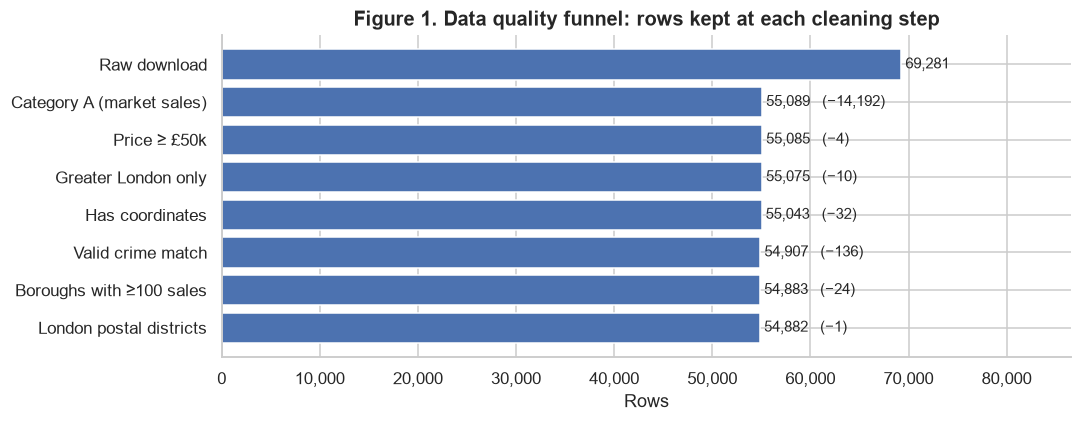

,step,rows,removed
0,Raw download,69281,0
1,Category A (market sales),55089,14192
2,Price ≥ £50k,55085,4
3,Greater London only,55075,10
4,Has coordinates,55043,32
5,Valid crime match,54907,136
6,Boroughs with ≥100 sales,54883,24
7,London postal districts,54882,1


In [3]:
f = pd.DataFrame(funnel, columns=["step", "rows"])
f["removed"] = (-f["rows"].diff()).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(f["step"][::-1], f["rows"][::-1], color="#4C72B0")
for y, (r, d) in enumerate(zip(f["rows"][::-1], f["removed"][::-1])):
    ax.text(r + 400, y, f"{r:,}" + (f"   (−{d:,})" if d else ""), va="center", fontsize=10)
ax.set_xlim(0, f["rows"].max() * 1.25)
ax.set_title("Figure 1. Data quality funnel: rows kept at each cleaning step")
ax.set_xlabel("Rows"); ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()
f

**What it shows.** 20.8% of the raw extract is removed, almost all of it (14,192 rows) by excluding Land Registry *category B* transactions. Category B covers repossessions, buy-to-let portfolio purchases and transfers to companies; the largest single record in the raw file was a £793m sale of an entire Westminster building. The remaining rules remove £1 transfers, stray non-London records, sales without geocodes, and LSOAs missing from the crime data.

**Why it matters.** Category B prices do not reflect what an individual buyer pays for a single home, and their inclusion would inflate error metrics and bias the model upward at the top end. Industry AVMs and the official UK House Price Index both restrict to standard (category A) transactions for the same reason.

**Coverage note.** Because the extract was filtered on *town = LONDON*, it covers London **postal** districts. Outer boroughs that use other postcode areas (CR for Croydon, BR for Bromley, HA for Harrow) are under-represented or absent. The model's scope should be stated as "London postal districts", not "Greater London".

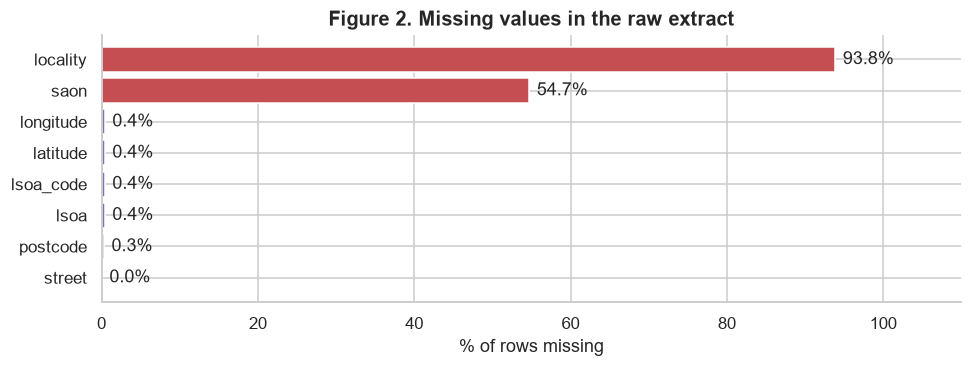

In [4]:
miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(miss.index[::-1], miss.values[::-1] * 100, color=["#C44E52" if v > 0.5 else "#8172B3" for v in miss.values[::-1]])
for y, v in enumerate(miss.values[::-1]):
    ax.text(v * 100 + 1, y, f"{v:.1%}", va="center")
ax.set_xlim(0, 110); ax.set_xlabel("% of rows missing")
ax.set_title("Figure 2. Missing values in the raw extract")
plt.tight_layout(); plt.show()

**What it shows.** Two columns are mostly empty: `locality` (≈93%) and `saon` (≈55%). Missing values elsewhere are below 0.5%.

**Interpretation.** These are *structural* gaps, not data-quality failures, and they need opposite treatments:
- `saon` (the flat or unit identifier) is empty because whole houses do not have one. The gap is informative and is converted into features (unit inside a building, floor level), never imputed.
- `locality` is an optional address line rarely used in London; it duplicates information already in postcode, LSOA and borough, and is dropped.

The small number of rows missing postcodes or coordinates (≈0.4%) are removed rather than imputed: location is the most important input to a valuation, and an estimated location would introduce error exactly where the model is most sensitive.

## 2. The target variable: sale price

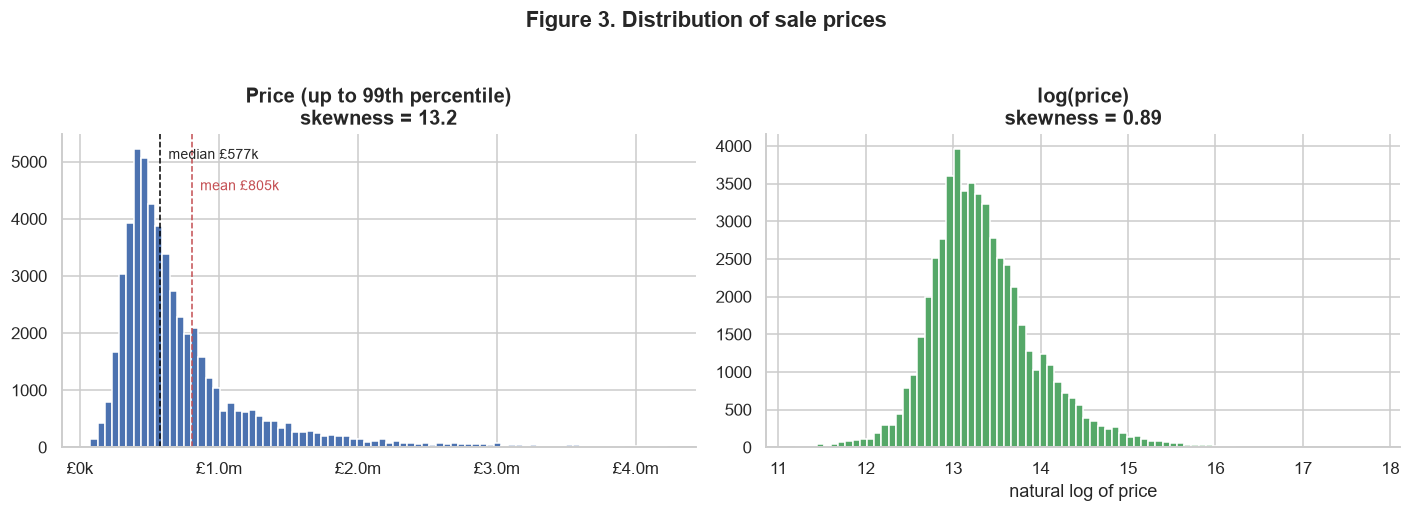

count        54,882
mean        805,399
std         974,031
min          72,500
5%          275,000
25%         423,000
50%         577,200
75%         860,000
95%       1,949,850
99%       4,225,779
max      53,000,000
Name: price, dtype: str

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cap = df["price"].quantile(0.99)
axes[0].hist(df.loc[df["price"] <= cap, "price"], bins=80, color="#4C72B0", edgecolor="white")
axes[0].axvline(df["price"].median(), color="black", ls="--", lw=1)
axes[0].axvline(df["price"].mean(), color="#C44E52", ls="--", lw=1)
axes[0].text(df["price"].median(), axes[0].get_ylim()[1]*0.92, f"  median £{df['price'].median()/1e3:,.0f}k", fontsize=9)
axes[0].text(df["price"].mean(), axes[0].get_ylim()[1]*0.82, f"  mean £{df['price'].mean()/1e3:,.0f}k", color="#C44E52", fontsize=9)
axes[0].xaxis.set_major_formatter(gbp)
axes[0].set_title(f"Price (up to 99th percentile)\nskewness = {df['price'].skew():.1f}")
axes[1].hist(df["log_price"], bins=80, color="#55A868", edgecolor="white")
axes[1].set_title(f"log(price)\nskewness = {df['log_price'].skew():.2f}")
axes[1].set_xlabel("natural log of price")
fig.suptitle("Figure 3. Distribution of sale prices", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
df["price"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).apply(lambda v: f"{v:,.0f}")

**What it shows.** The median sale is £577k, but the mean is £805k, pulled up by a long tail: the top 1% of sales exceed £4.2m and the maximum is £53m. Raw prices have a skewness of 13.2. On the log scale the distribution is close to symmetric (skewness 0.9).

**Why it matters for modelling.**
- **Train on log price.** Valuation errors are naturally proportional (a £50k miss matters far more on a £300k flat than on a £5m house), and log targets turn proportional errors into additive ones. Industry AVM accuracy is usually reported in percentage terms, such as median absolute percentage error and the share of valuations within ±10% of the sale price, which aligns with a log target.
- **Report the median, not the mean.** The mean overstates the "typical" London sale by about 40%. This is why the ONS and Land Registry headline figures use medians or mix-adjusted indices.
- **High-value tail.** 74 sales above £10m remain. They are genuine prime transactions, but there are too few for a model to learn reliably. Common practice is either to cap model scope (e.g. "valid up to £5m") or to report accuracy separately by price band.

## 3. Property characteristics

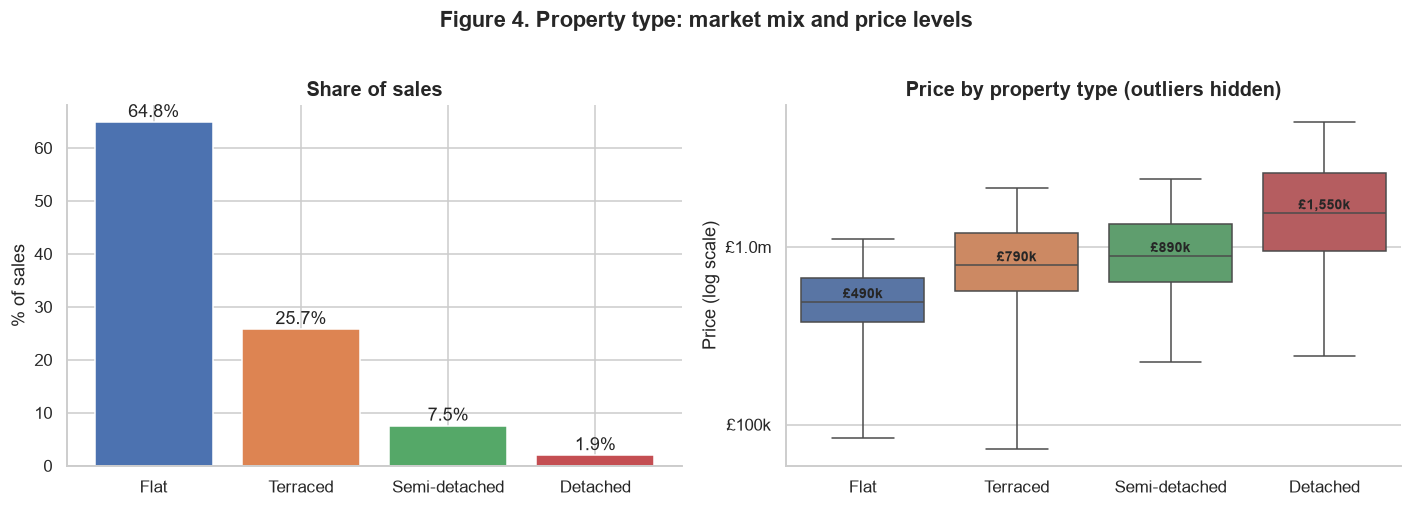

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
share = df["type_name"].value_counts(normalize=True).reindex(TYPE_ORDER)
axes[0].bar(share.index, share.values * 100, color=[PALETTE[t] for t in share.index])
for i, v in enumerate(share.values):
    axes[0].text(i, v * 100 + 1, f"{v:.1%}", ha="center")
axes[0].set_ylabel("% of sales"); axes[0].set_title("Share of sales")
sns.boxplot(data=df, x="type_name", y="price", order=TYPE_ORDER, palette=PALETTE, hue="type_name",
            legend=False, showfliers=False, ax=axes[1])
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(gbp)
axes[1].set_xlabel(""); axes[1].set_ylabel("Price (log scale)")
med = df.groupby("type_name")["price"].median().reindex(TYPE_ORDER)
for i, v in enumerate(med):
    axes[1].text(i, v * 1.05, f"£{v/1e3:,.0f}k", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Price by property type (outliers hidden)")
fig.suptitle("Figure 4. Property type: market mix and price levels", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**What it shows.** Flats make up 64.8% of transactions, terraced houses 25.7%, and semi-detached and detached houses together under 10%. Median prices step up sharply by type: flat £490k, terraced £790k, semi-detached £890k, detached £1.55m. The boxes overlap substantially, so type alone does not determine price.

**Why it matters.**
- **Flats dominate the data, so model accuracy will be driven by flats.** Headline metrics should also be reported by property type; otherwise strong flat performance can hide weak performance on the rare, expensive detached segment (only 1.9% of sales).
- **This mix is unusual.** Nationally, flats are a minority of sales; inner London is a flat market. A model trained here should not be applied to suburban or rural markets without retraining.
- **Overlapping ranges** show that location and size matter as much as type: a flat in Kensington can exceed a terraced house in Bexley several times over.

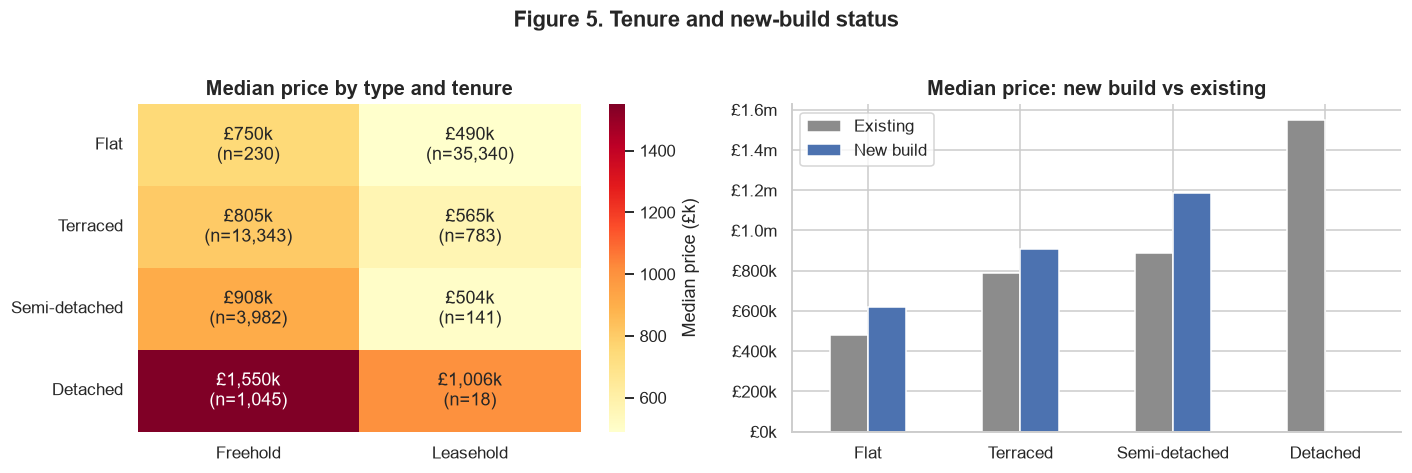

In [7]:
pv = df.pivot_table(index="type_name", columns="tenure", values="price", aggfunc="median").reindex(TYPE_ORDER)
cnt = df.pivot_table(index="type_name", columns="tenure", values="price", aggfunc="size").reindex(TYPE_ORDER)
pv.columns = cnt.columns = ["Freehold", "Leasehold"]
labels = pv.map(lambda v: f"£{v/1e3:,.0f}k") + "\n(n=" + cnt.map(lambda v: f"{v:,}") + ")"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
sns.heatmap(pv / 1e3, annot=labels, fmt="", cmap="YlOrRd", cbar_kws={"label": "Median price (£k)"}, ax=axes[0])
axes[0].set_title("Median price by type and tenure"); axes[0].set_xlabel(""); axes[0].set_ylabel("")
nb = df.groupby(["type_name", "new_build"])["price"].median().unstack().reindex(TYPE_ORDER)
nb.columns = ["Existing", "New build"]
nb.plot.bar(ax=axes[1], color=["#8C8C8C", "#4C72B0"], rot=0)
axes[1].yaxis.set_major_formatter(gbp); axes[1].set_xlabel(""); axes[1].set_title("Median price: new build vs existing")
fig.suptitle("Figure 5. Tenure and new-build status", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**What it shows.**
- **Tenure largely tracks property type:** 99.4% of flats are leasehold and 95% of houses are freehold. This is why `is_freehold` has the strongest correlation with log price of any numeric variable (r = 0.44): it is mostly a house-versus-flat flag.
- **The exceptions are where the signal is.** Leasehold terraced houses (783 sales) have a median of £565k against £805k for freehold, about 30% lower. Leasehold houses are often former council stock, shared-ownership units or homes with onerous lease terms, all of which lenders and buyers discount. Freehold flats (230 sales) carry a premium, typically because the buyer acquires a whole small building.
- **New builds sell at a premium:** 5.2% of sales are new builds. Comparing like with like (same postcode district and property type), new builds sell for roughly 30% more than existing homes.

**Why it matters.** Include *type × tenure* as an interaction feature rather than relying on the model to discover it. Treat the new-build premium with care: part of it reflects genuine quality (modern specification, warranties) and part reflects developer pricing that often does not hold on resale. Lenders commonly apply a "new-build premium" haircut for this reason, so the model's new-build valuations should be monitored separately.

## 4. Geography

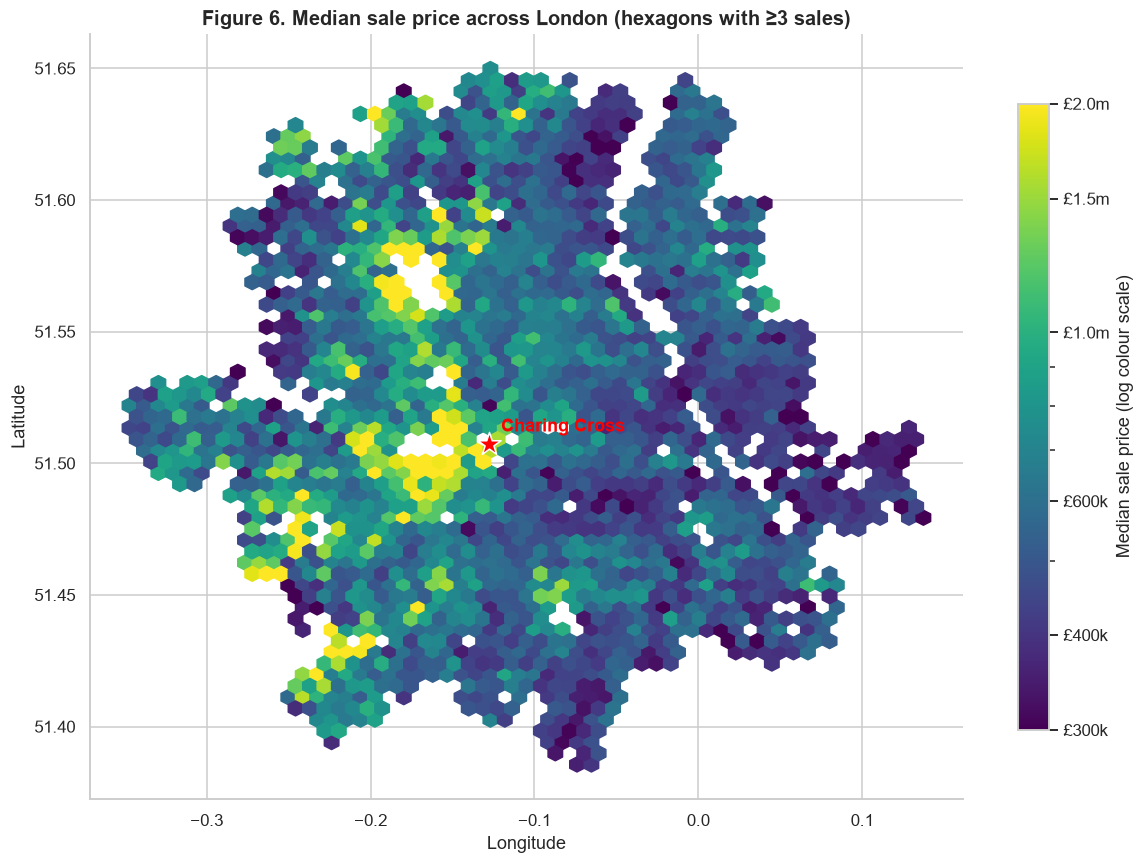

In [8]:
fig, ax = plt.subplots(figsize=(11, 8))
hb = ax.hexbin(df["longitude"], df["latitude"], C=df["price"], reduce_C_function=np.median,
               gridsize=55, cmap="viridis", mincnt=3, norm=plt.matplotlib.colors.LogNorm(vmin=3e5, vmax=2e6))
cb = fig.colorbar(hb, ax=ax, shrink=0.8); cb.set_label("Median sale price (log colour scale)")
cb.set_ticks([3e5, 4e5, 6e5, 1e6, 1.5e6, 2e6]); cb.ax.yaxis.set_major_formatter(gbp); cb.ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.scatter([-0.1278], [51.5074], marker="*", s=250, color="red", edgecolor="white", zorder=5)
ax.annotate("Charing Cross", (-0.1278, 51.5074), xytext=(8, 8), textcoords="offset points", color="red", fontweight="bold")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(1 / np.cos(np.radians(51.5)))
ax.set_title("Figure 6. Median sale price across London (hexagons with ≥3 sales)")
plt.tight_layout(); plt.show()

**What it shows.** Prices form a clear spatial pattern: a high-value core spreading west and south-west (Westminster, Kensington and Chelsea, Hammersmith, Richmond), with lower values to the east and south-east. The Thames, the 19th-century development pattern and transport links are all visible in the shape of the map.

**Why it matters.** Location is the main source of variation after property type, and it is not a simple function of distance: at the same distance from the centre, west London is substantially more expensive than east London. The model therefore needs features that capture *direction* as well as distance (raw coordinates, rotated coordinates, postcode district or borough), not distance alone.

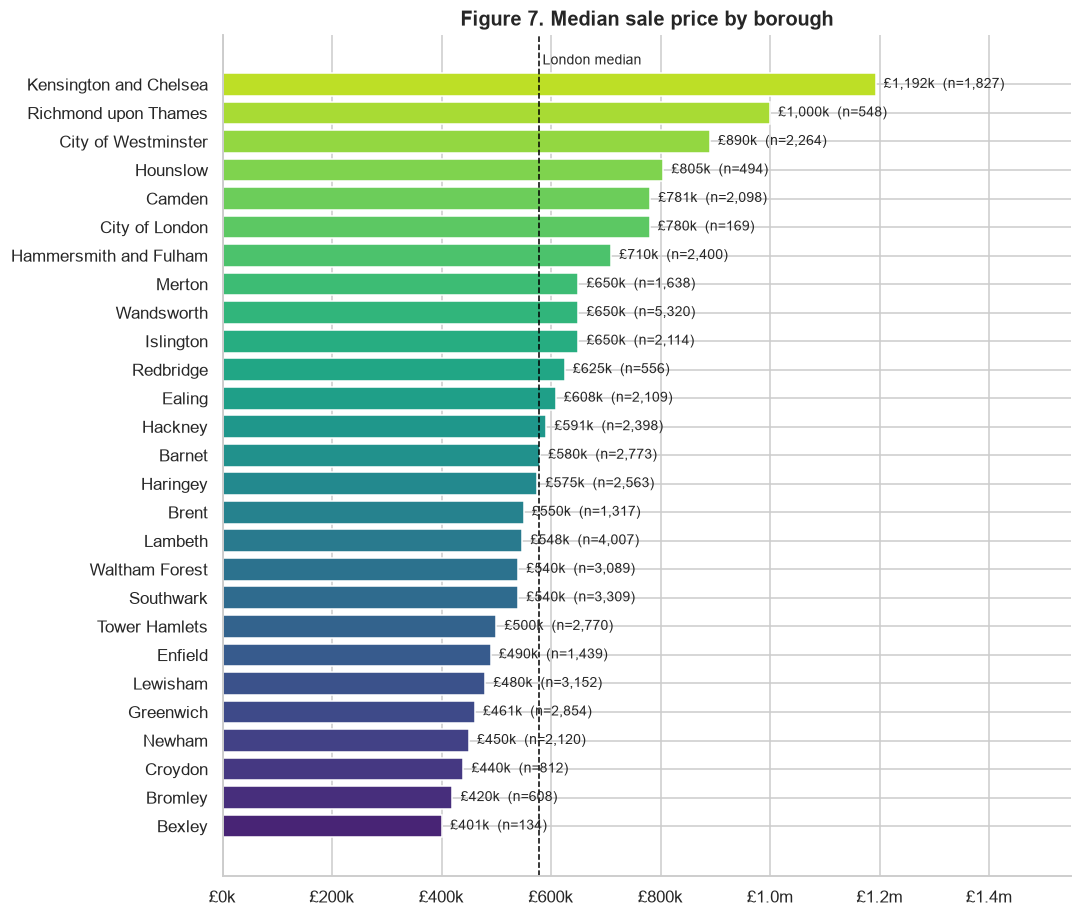

In [9]:
b = df.groupby("borough")["price"].agg(["median", "size"]).sort_values("median")
fig, ax = plt.subplots(figsize=(10, 8.5))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(b)))
ax.barh(b.index, b["median"], color=colors)
for y, (m, n) in enumerate(zip(b["median"], b["size"])):
    ax.text(m + 15000, y, f"£{m/1e3:,.0f}k  (n={n:,})", va="center", fontsize=9)
ax.axvline(df["price"].median(), color="black", ls="--", lw=1)
ax.text(df["price"].median(), len(b) - 0.3, " London median", fontsize=9)
ax.xaxis.set_major_formatter(gbp); ax.set_xlim(0, b["median"].max() * 1.3)
ax.set_title("Figure 7. Median sale price by borough")
plt.tight_layout(); plt.show()

**What it shows.** Borough medians range from £401k (Bexley) to £1.19m (Kensington and Chelsea), a threefold spread. Wandsworth has the most transactions in the sample (5,320). Sample sizes are very uneven: Bexley (134), the City of London (169) and Hounslow (494) are thin because only their parts with London postcodes are included.

**Why it matters.**
- Borough medians mix property types. Part of Kensington and Chelsea's premium is genuine location value and part is that it sells more large homes. Comparisons should be **mix-adjusted** (for example, flats only) before drawing conclusions about area value; this is the same reason the official House Price Index uses mix adjustment.
- Boroughs with few sales will have less reliable valuations. A production AVM attaches a confidence score to each estimate; low local sample size is one of the main reasons for low confidence.

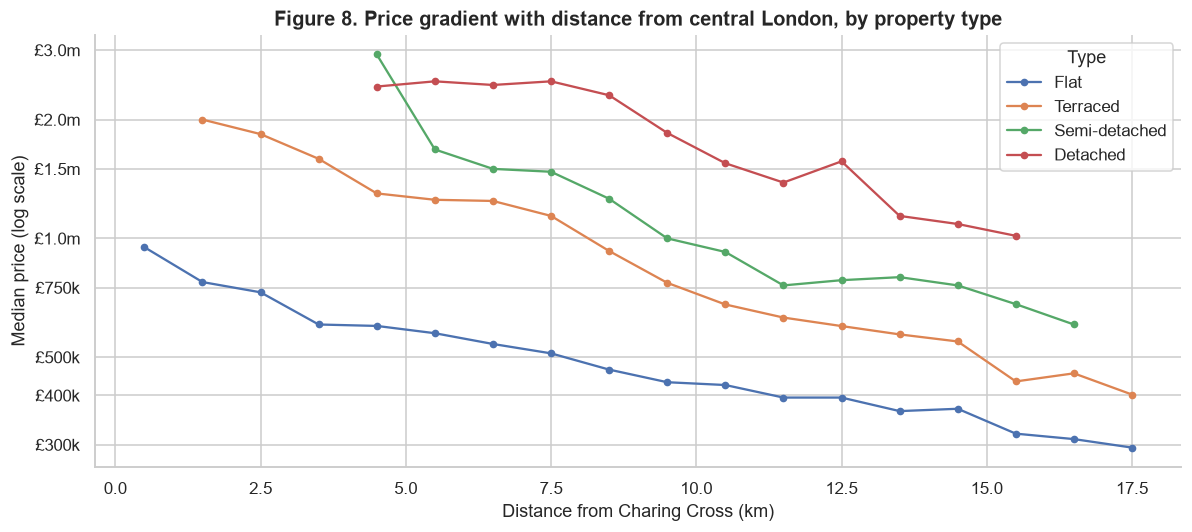

In [10]:
bins = np.arange(0, 21, 1)
df["km_bin"] = pd.cut(df["km_to_centre"], bins)
g = df.groupby(["km_bin", "type_name"], observed=True)["price"].agg(["median", "size"]).reset_index()
g = g[g["size"] >= 30]; g["km"] = g["km_bin"].apply(lambda i: i.mid)
fig, ax = plt.subplots(figsize=(11, 5))
for t in TYPE_ORDER:
    s = g[g["type_name"] == t]
    ax.plot(s["km"], s["median"], marker="o", ms=4, label=t, color=PALETTE[t])
ax.set_yscale("log"); ax.set_yticks([3e5, 4e5, 5e5, 7.5e5, 1e6, 1.5e6, 2e6, 3e6]); ax.yaxis.set_major_formatter(gbp); ax.yaxis.set_minor_formatter(mtick.NullFormatter())
ax.set_xlabel("Distance from Charing Cross (km)"); ax.set_ylabel("Median price (log scale)")
ax.set_title("Figure 8. Price gradient with distance from central London, by property type")
ax.legend(title="Type"); plt.tight_layout(); plt.show()

**What it shows.** Prices fall steadily with distance from the centre for every property type. For all sales, the median drops from £850k within 2 km to £456k beyond 15 km. The gradient is steepest for flats: £750k within 3 km falls to £395k beyond 10 km, nearly halving.

**Why it matters.** This "bid-rent" gradient is one of the most robust relationships in urban economics: buyers pay more to be closer to jobs and amenities. Distance to the centre is a strong, easily explained feature (r = −0.26 with log price on its own). The curves are not straight lines on the log scale, which favours tree-based models (such as gradient boosting) that can learn non-linear shapes without manual transformation.

## 5. Time and market activity

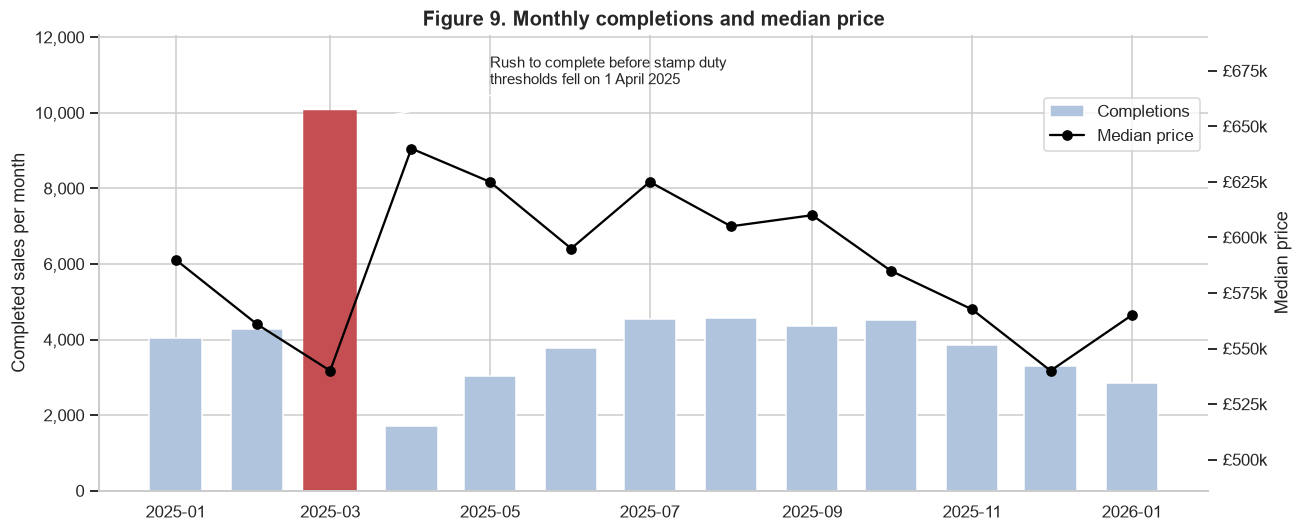

,sales,median
month,,
2025-01-01,4044,"£590,000"
2025-02-01,4291,"£561,000"
2025-03-01,10053,"£540,000"
2025-04-01,1711,"£640,000"
2025-05-01,3025,"£625,000"
2025-06-01,3771,"£595,000"
2025-07-01,4536,"£625,000"
2025-08-01,4580,"£605,000"
2025-09-01,4356,"£610,000"


In [11]:
m = df.groupby("month").agg(sales=("price", "size"), median=("price", "median"))
m.index = m.index.to_timestamp()
fig, ax1 = plt.subplots(figsize=(12, 5))
bars = ax1.bar(m.index, m["sales"], width=20, color="#B0C4DE", label="Completions")
bars[2].set_color("#C44E52")
ax1.set_ylim(0, m["sales"].max() * 1.2); ax1.set_ylabel("Completed sales per month"); ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax2 = ax1.twinx(); ax2.plot(m.index, m["median"], color="black", marker="o", label="Median price")
ax2.yaxis.set_major_formatter(gbp); ax2.set_ylabel("Median price"); ax2.grid(False)
ax2.set_ylim(m["median"].min() * 0.9, m["median"].max() * 1.08)
ax1.annotate("Rush to complete before stamp duty\nthresholds fell on 1 April 2025", xy=(m.index[2] + pd.Timedelta(days=10), m["sales"].iloc[2] * 0.97),
             xytext=(m.index[4], m["sales"].iloc[2] * 1.07), arrowprops=dict(arrowstyle="->"), fontsize=10)
ax1.set_title("Figure 9. Monthly completions and median price")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", bbox_to_anchor=(1, 0.88)); plt.tight_layout(); plt.show()
m.assign(median=m["median"].map(lambda v: f"£{v:,.0f}"))

**What it shows.** Completions are normally 3,000–4,600 a month, but March 2025 reached 10,053, then April fell to 1,711. On 1 April 2025 the temporary stamp duty relief ended: the nil-rate threshold fell from £250,000 to £125,000, and first-time buyer relief was cut from £425,000 to £300,000. Buyers brought completions forward to avoid the higher tax.

The median price moves *against* volume: it dipped to £540k in March and jumped to £640k in April. The final months (December 2025 – January 2026) also show lower volumes, partly seasonal and partly because recent sales take several weeks to be registered with the Land Registry.

**Why it matters.**
- **Policy events distort short-term data.** An analyst reading the median price series naively would conclude prices fell 4% in March and rose 19% in April. Neither is true (see Figure 10).
- **Registration lag:** the most recent one or two months are always incomplete in Land Registry data. A production pipeline should flag them as provisional rather than reporting falling activity.
- **Model validation:** if the model is tested on the most recent months, test-set composition will differ from training. Time-based splits remain correct, but performance should be checked by month.

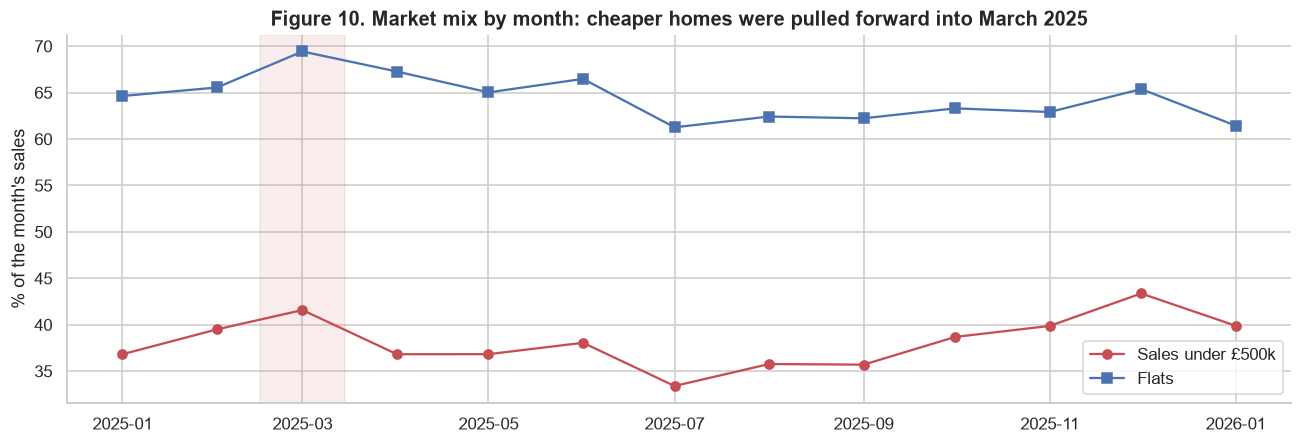

In [12]:
mix = df.groupby("month").agg(share_under_500k=("price", lambda s: (s < 500_000).mean()),
                              share_flats=("property_type", lambda s: (s == "F").mean()))
mix.index = mix.index.to_timestamp()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(mix.index, mix["share_under_500k"] * 100, marker="o", label="Sales under £500k", color="#C44E52")
ax.plot(mix.index, mix["share_flats"] * 100, marker="s", label="Flats", color="#4C72B0")
ax.axvspan(mix.index[2] - pd.Timedelta(days=14), mix.index[2] + pd.Timedelta(days=14), color="#C44E52", alpha=0.1)
ax.set_ylabel("% of the month's sales"); ax.legend()
ax.set_title("Figure 10. Market mix by month: cheaper homes were pulled forward into March 2025")
plt.tight_layout(); plt.show()

**What it shows.** In March 2025, the share of sales under £500k rose to 41.6% (from 36.8% in January) and the share of flats rose to 69.4% (from 64.6%). Both shares dropped back in April. (December also shows a higher share of cheaper sales, consistent with the usual seasonal slowdown at the top end over the holiday period and with incomplete registration of the latest months.)

**Interpretation.** The stamp duty change hit cheaper homes and first-time buyers hardest, so those purchases were pulled forward most. The March dip and April spike in median price are therefore **composition effects**, not changes in value. A like-for-like home did not become cheaper in March.

**Why it matters.** This is the central reason the industry uses *mix-adjusted* or *repeat-sales* indices rather than raw medians to track prices. For the model, it means a monthly price index should be estimated with property characteristics controlled for, and a `before_stamp_duty_change` flag can help the model separate the policy distortion from genuine trend.

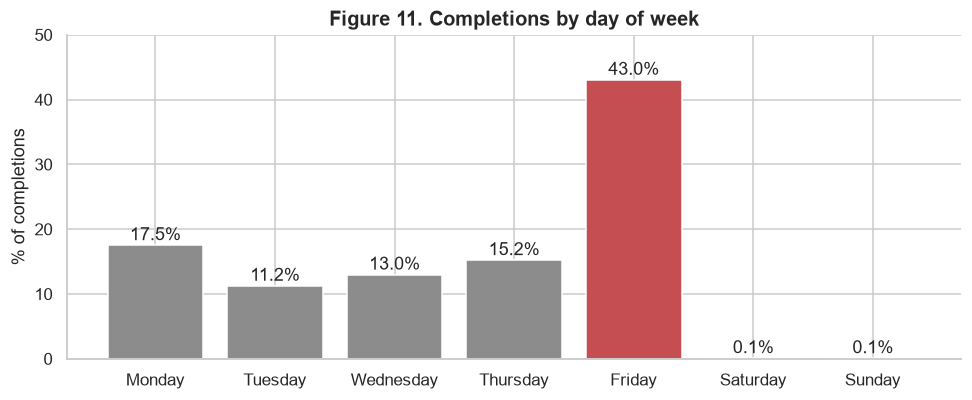

In [13]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = df["weekday"].value_counts(normalize=True).reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(wd.index, wd.values * 100, color=["#C44E52" if d == "Friday" else "#8C8C8C" for d in wd.index])
for i, v in enumerate(wd.values):
    ax.text(i, v * 100 + 0.8, f"{v:.1%}", ha="center")
ax.set_ylim(0, 50); ax.set_ylabel("% of completions"); ax.set_title("Figure 11. Completions by day of week")
plt.tight_layout(); plt.show()

**What it shows.** 43% of completions happen on a Friday and virtually none at weekends.

**Interpretation.** Completion is the legal transfer date, which in England and Wales is also typically moving day. Buyers choose Fridays so they can move over the weekend, and conveyancers and banks do not transfer funds at weekends.

**Why it matters.** This is a useful sanity check that the dates are completion dates, not offer or listing dates. It also highlights that Land Registry prices lag the market: the price was agreed at offer, typically two to four months earlier. Day of week has no bearing on value and is excluded from the model.

## 6. What the address text reveals

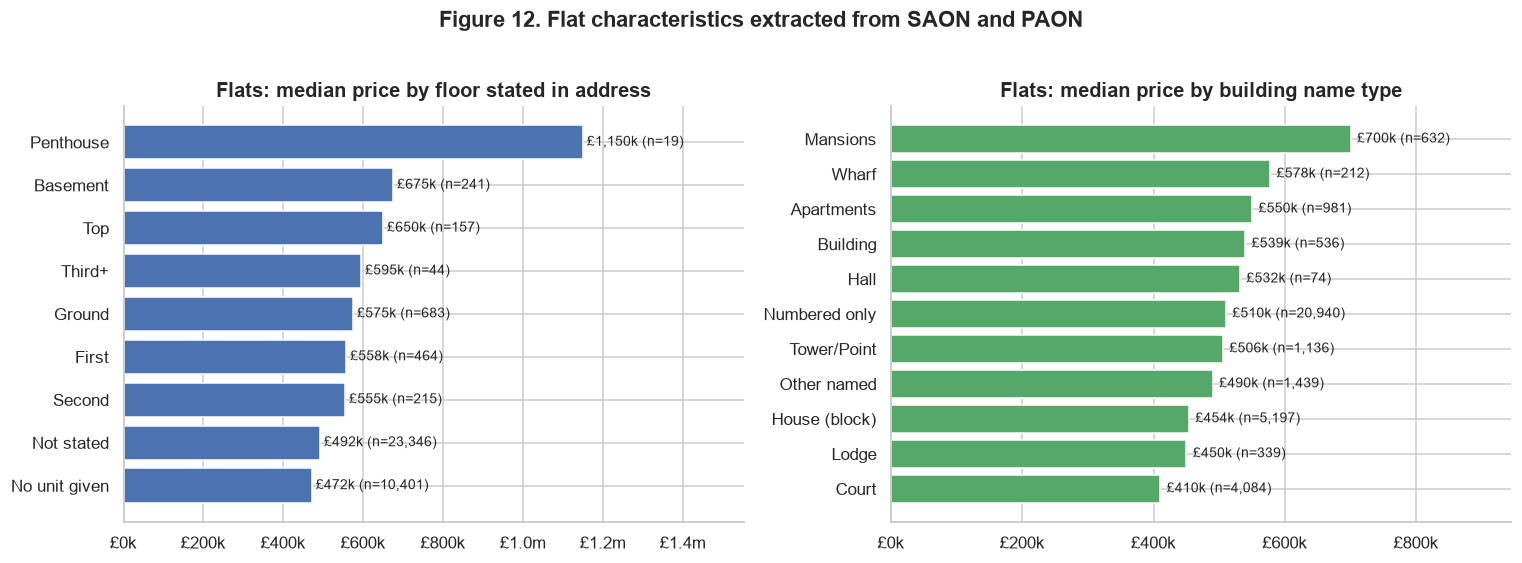

In [14]:
fl = df[df["property_type"] == "F"].copy()
fl["floor_level"] = fl["floor_level"].replace({"Whole property": "No unit given"})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
f1 = fl.groupby("floor_level")["price"].agg(["median", "size"])
f1 = f1[f1["size"] >= 15].sort_values("median")
axes[0].barh(f1.index, f1["median"], color="#4C72B0")
for y, (v, n) in enumerate(zip(f1["median"], f1["size"])):
    axes[0].text(v + 10000, y, f"£{v/1e3:,.0f}k (n={n:,})", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(gbp); axes[0].set_xlim(0, f1["median"].max() * 1.35)
axes[0].set_title("Flats: median price by floor stated in address")
f2 = fl.groupby("building_type")["price"].agg(["median", "size"])
f2 = f2[f2["size"] >= 50].sort_values("median")
axes[1].barh(f2.index, f2["median"], color="#55A868")
for y, (v, n) in enumerate(zip(f2["median"], f2["size"])):
    axes[1].text(v + 10000, y, f"£{v/1e3:,.0f}k (n={n:,})", va="center", fontsize=9)
axes[1].xaxis.set_major_formatter(gbp); axes[1].set_xlim(0, f2["median"].max() * 1.35)
axes[1].set_title("Flats: median price by building name type")
fig.suptitle("Figure 12. Flat characteristics extracted from SAON and PAON", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**What it shows.**
- **Building type** separates flat prices clearly. Flats in buildings named "Court" have a median of £410k and those in "House" blocks £454k; these names are common on post-war and former local-authority estates. "Mansions" (Victorian and Edwardian mansion blocks, concentrated in prime west and north London) reach £700k, and "Wharf" conversions £578k.
- **Floor level** is only stated for about 5% of flats; "Not stated" means the address gives a unit number but no floor (e.g. "FLAT 5"), and "No unit given" means the flat is identified in the house number instead (e.g. "38A"); most addresses just say "FLAT 5". Where it is stated, penthouses (£1.15m, n=19) and top-floor flats (£650k) command premiums. Basement flats show a surprisingly high median (£675k), not because basements are desirable, but because addresses written as "Basement Flat" are typical of large period houses in expensive inner areas: their median distance to the centre is 5.8 km versus 7.3 km for flats overall.

**Why it matters.** Free-text address fields are routinely ignored, yet here they act as proxies for building age, construction type and estate status, which are not available anywhere else in the data. The basement result is a warning against reading single-variable averages causally: the model must see location and floor together to learn the true floor effect.

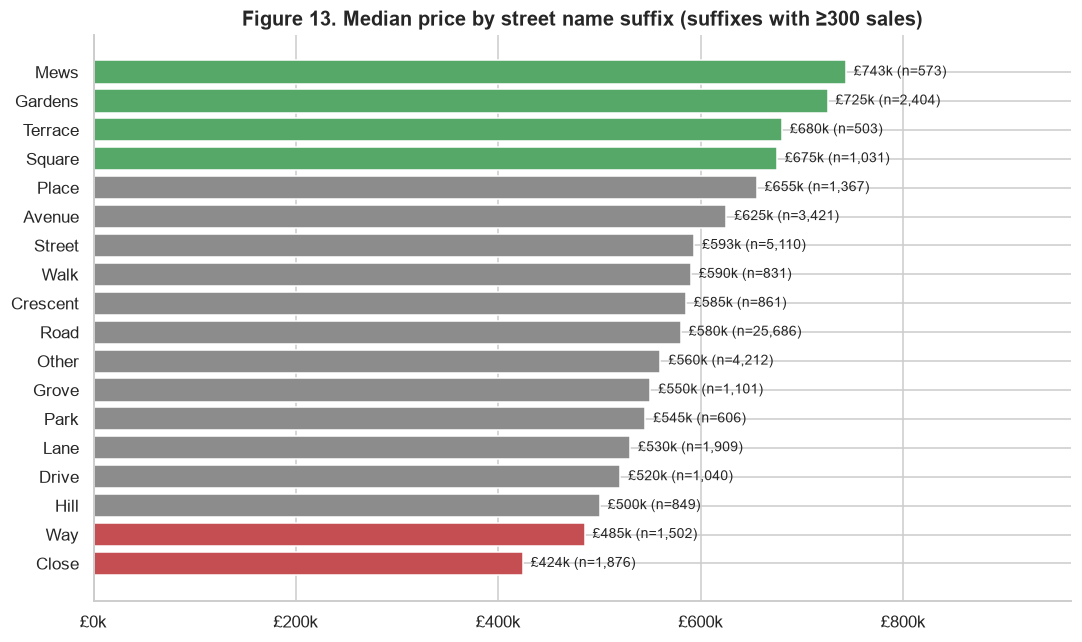

In [15]:
s = df.groupby("street_type")["price"].agg(["median", "size"]).sort_values("median")
s.index = s.index.str.title()
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#C44E52" if i in ("Close", "Way") else "#55A868" if i in ("Mews", "Gardens", "Terrace", "Square") else "#8C8C8C" for i in s.index]
ax.barh(s.index, s["median"], color=colors)
for y, (v, n) in enumerate(zip(s["median"], s["size"])):
    ax.text(v + 8000, y, f"£{v/1e3:,.0f}k (n={n:,})", va="center", fontsize=9)
ax.xaxis.set_major_formatter(gbp); ax.set_xlim(0, s["median"].max() * 1.3)
ax.set_title("Figure 13. Median price by street name suffix (suffixes with ≥300 sales)")
plt.tight_layout(); plt.show()

**What it shows.** "Mews" (£743k), "Gardens" (£725k), "Terrace" (£680k) and "Square" (£675k) sit well above "Road" (£580k, the most common suffix with 25,686 sales), while "Close" (£424k) and "Way" (£485k) sit at the bottom.

**Interpretation.** Street names encode when and how a street was built. Mews, squares and terraces are typical of Georgian and Victorian planned development in inner London; closes and ways are typical of post-war estates and cul-de-sacs, often with smaller homes and further from the centre.

**Why it matters.** This is a cheap, interpretable feature that captures neighbourhood character. Group rare suffixes into "Other" (as here) to avoid the model fitting to tiny categories.

## 7. Crime and price

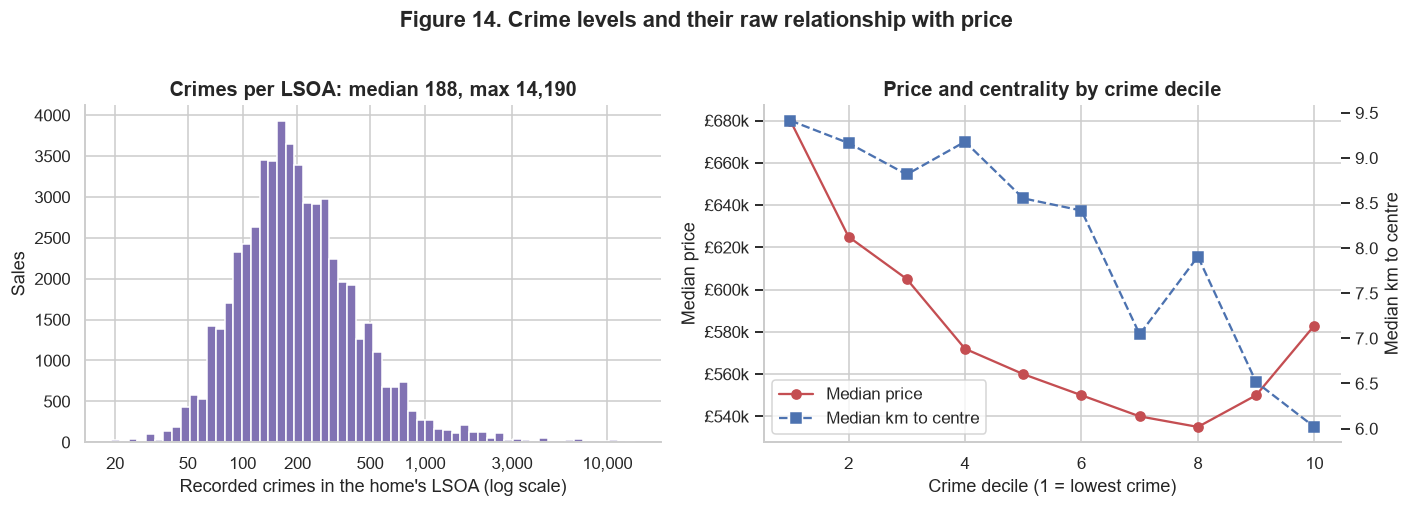

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(np.log10(df["crimes"]), bins=60, color="#8172B3", edgecolor="white")
ticks = [20, 50, 100, 200, 500, 1000, 3000, 10000]
axes[0].set_xticks(np.log10(ticks)); axes[0].set_xticklabels([f"{t:,}" for t in ticks])
axes[0].set_xlabel("Recorded crimes in the home's LSOA (log scale)"); axes[0].set_ylabel("Sales")
axes[0].set_title(f"Crimes per LSOA: median {df['crimes'].median():.0f}, max {int(df['crimes'].max()):,}")
df["crime_decile"] = pd.qcut(df["crimes"], 10, labels=False) + 1
d = df.groupby("crime_decile").agg(price=("price", "median"), km=("km_to_centre", "median"))
axes[1].plot(d.index, d["price"], marker="o", color="#C44E52", label="Median price")
axes[1].yaxis.set_major_formatter(gbp); axes[1].set_xlabel("Crime decile (1 = lowest crime)")
axes[1].set_ylabel("Median price")
ax2 = axes[1].twinx(); ax2.plot(d.index, d["km"], marker="s", ls="--", color="#4C72B0", label="Median km to centre")
ax2.set_ylabel("Median km to centre"); ax2.grid(False)
axes[1].set_title("Price and centrality by crime decile")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="lower left")
fig.suptitle("Figure 14. Crime levels and their raw relationship with price", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**What it shows.** Crime counts are extremely skewed: a typical LSOA records about 190 crimes over the 13 months, while a few central LSOAs exceed 14,000 (around shopping and nightlife hubs such as the West End). Across deciles, price falls as crime rises, from £680k in the lowest-crime decile to £535k in decile 8, then **rises again** to £583k in the highest-crime decile. Meanwhile, the highest-crime deciles are clearly closer to the centre (median 6.0 km versus 9.4 km).

**Interpretation.** The U-shape is a classic case of *confounding*. Recorded crime measures incidents, not risk to residents, and incidents scale with footfall. Central areas attract huge numbers of visitors, which inflates crime counts in some of London's most valuable places. Centrality drives both crime and price, so the raw relationship mixes two different effects.

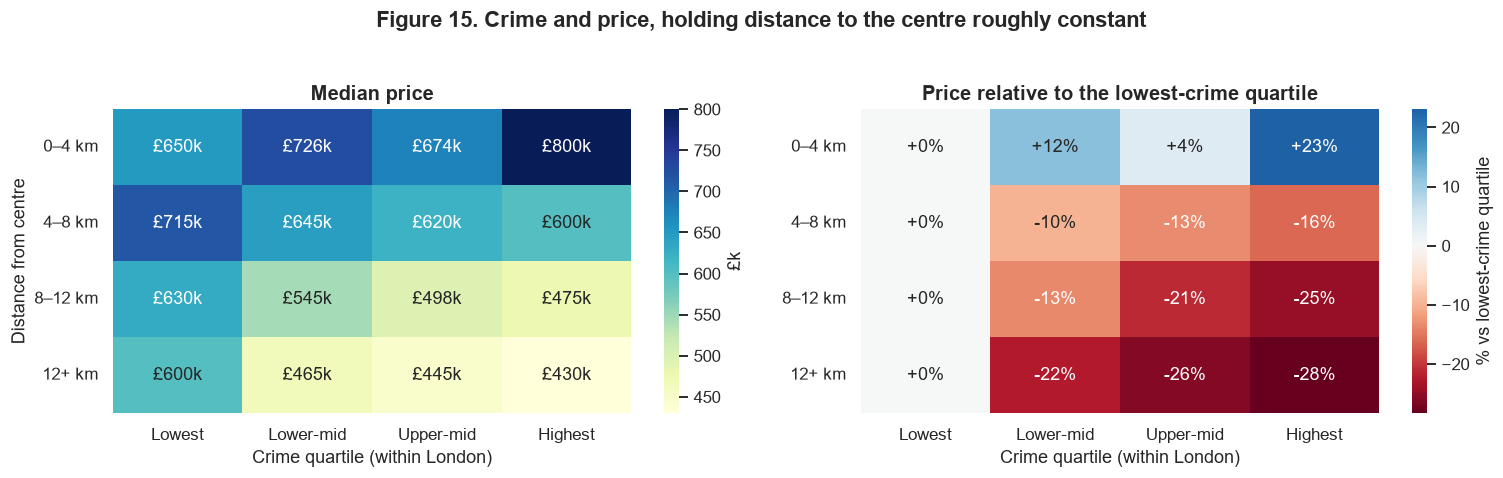

In [17]:
df["distance_band"] = pd.cut(df["km_to_centre"], [0, 4, 8, 12, 25], labels=["0–4 km", "4–8 km", "8–12 km", "12+ km"])
df["crime_quartile"] = pd.qcut(df["crimes"], 4, labels=["Lowest", "Lower-mid", "Upper-mid", "Highest"])
pv = df.pivot_table(index="distance_band", columns="crime_quartile", values="price", aggfunc="median", observed=True)
rel = pv.div(pv["Lowest"], axis=0) - 1
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(pv / 1e3, annot=pv.map(lambda v: f"£{v/1e3:,.0f}k"), fmt="", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "£k"})
axes[0].set_title("Median price"); axes[0].set_xlabel("Crime quartile (within London)"); axes[0].set_ylabel("Distance from centre")
sns.heatmap(rel * 100, annot=rel.map(lambda v: f"{v:+.0%}"), fmt="", cmap="RdBu", center=0, ax=axes[1], cbar_kws={"label": "% vs lowest-crime quartile"})
axes[1].set_title("Price relative to the lowest-crime quartile"); axes[1].set_xlabel("Crime quartile (within London)"); axes[1].set_ylabel("")
for a in axes: a.tick_params(axis="y", rotation=0)
fig.suptitle("Figure 15. Crime and price, holding distance to the centre roughly constant", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**What it shows.** Once distance is held roughly constant, the expected relationship appears everywhere except the centre:
- **4–8 km:** the highest-crime quartile sells 16% below the lowest (£600k vs £715k).
- **8–12 km:** 25% below (£475k vs £630k).
- **12 km and beyond:** 28% below (£430k vs £600k).
- **Within 4 km:** the relationship reverses, with the highest-crime areas 23% *above* the lowest. In the centre, high recorded crime marks the busiest and most desirable districts.

**Why it matters.**
- **Never interpret a single correlation as an effect.** Raw crime counts correlate slightly *positively* with log price (+0.06; burglaries +0.07), which taken at face value would suggest crime raises prices. That conclusion is wrong for most of London.
- **Tree-based models can capture this interaction** (crime matters differently near the centre) automatically; a linear model would need an explicit crime × distance interaction term.
- **Better crime measures:** a production model would use crime *rates* (per resident population) and resident-relevant crime types such as burglary, and would exclude categories like shoplifting that track retail footfall.

## 8. Summary of numeric relationships

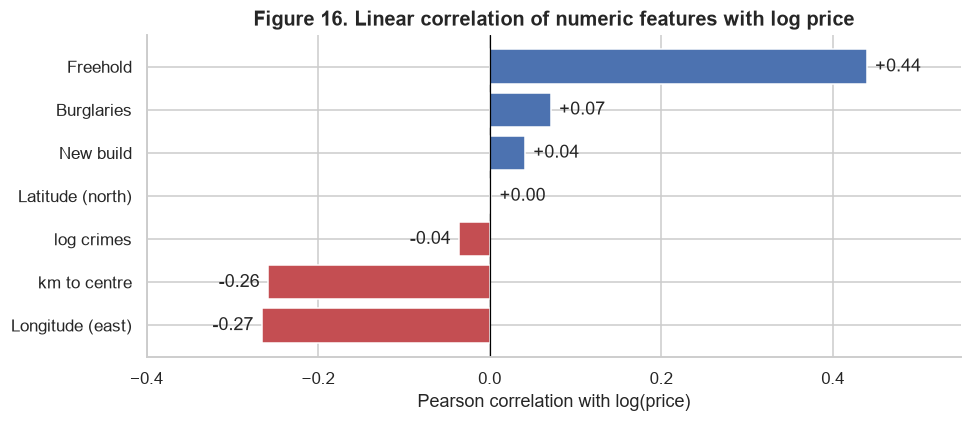

In [18]:
num = pd.DataFrame({
    "Freehold": df["is_freehold"], "New build": df["is_new_build"],
    "km to centre": df["km_to_centre"], "Longitude (east)": df["longitude"], "Latitude (north)": df["latitude"],
    "log crimes": np.log(df["crimes"]), "Burglaries": df["burglaries"],
})
corr = num.corrwith(df["log_price"]).sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(corr.index, corr.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in corr.values])
for y, v in enumerate(corr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right")
ax.axvline(0, color="black", lw=0.8); ax.set_xlim(-0.4, 0.55)
ax.set_xlabel("Pearson correlation with log(price)")
ax.set_title("Figure 16. Linear correlation of numeric features with log price")
plt.tight_layout(); plt.show()

**What it shows.** Freehold status (+0.44), longitude (−0.27: further east is cheaper) and distance to the centre (−0.26) have the strongest linear relationships with log price. Latitude, crime counts and new-build status show near-zero linear correlation.

**How to read this correctly.** A near-zero correlation does **not** mean a variable is unimportant. Latitude matters (north-west and south-west are expensive, north-east and south-east less so), but the effect is not linear in one direction. Crime matters a great deal outside the centre (Figure 15), but its sign flips near the centre. New builds carry a ~30% premium like-for-like (Figure 5), but they are concentrated in cheaper eastern areas, which hides the premium in a raw correlation. Correlation screens are a starting point; final feature selection should be based on model-based importance and validation performance.

---
# Part II — Advanced analysis

Part I described the market one variable at a time. Part II asks the questions a valuation or risk team would ask next: how much of price is location, what each characteristic is worth once everything else is held constant, how prices moved after removing mix effects, and how accurately a simple comparable-sales valuation performs before any machine learning.

In [19]:
import statsmodels.api as sm
from sklearn.neighbors import NearestNeighbors

pc = df["postcode"].str.upper().str.strip()
df["pc_sector"] = pc.str[:-2].str.strip()
df["tt"] = df["type_name"] + " · " + df["tenure"].map({"F": "freehold", "L": "leasehold"})
df["nb"] = df["new_build"].map({"Y": "New build", "N": "Existing"})
df["mon"] = df["month"].astype(str)
df["cq"] = pd.qcut(df["crimes"], 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"]).astype(str)
df["street_sfx"] = df["street_type"].str.title()


def fe_r2(data, cat_x, group):
    """R² of log price on dummies(cat_x) plus fixed effects for `group` (within-transformation)."""
    X = pd.get_dummies(data[cat_x], drop_first=True).astype(float)
    y = data["log_price"].astype(float)
    if group is None:
        Xd, yd = X - X.mean(), y - y.mean()
    else:
        g = data[group]
        Xd, yd = X - X.groupby(g).transform("mean"), y - y.groupby(g).transform("mean")
    beta, *_ = np.linalg.lstsq(Xd.values, yd.values, rcond=None)
    resid = yd.values - Xd.values @ beta
    return 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()


def hedonic(data, cats, base, group):
    """Hedonic regression: log price on dummies (vs chosen base levels) with `group` fixed effects.
    Returns % premiums with 95% CIs (SEs clustered by group), total R², and residuals."""
    X = pd.concat([pd.get_dummies(data[c], prefix=c, prefix_sep="=").astype(float).drop(columns=f"{c}={base[c]}")
                   for c in cats], axis=1)
    y, g = data["log_price"].astype(float), data[group]
    Xd, yd = X - X.groupby(g).transform("mean"), y - y.groupby(g).transform("mean")
    Xd = Xd.loc[:, Xd.abs().sum() > 0]
    if g.nunique() > 1:
        m = sm.OLS(yd.values, Xd.values).fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(g)[0]})
    else:
        m = sm.OLS(yd.values, Xd.values).fit(cov_type="HC1")
    ci = m.conf_int()
    t = pd.DataFrame({"pct": np.exp(m.params) - 1, "lo": np.exp(ci[:, 0]) - 1, "hi": np.exp(ci[:, 1]) - 1}, index=Xd.columns)
    resid = pd.Series(yd.values - Xd.values @ m.params, index=data.index)
    return t, 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum(), resid


def comps_avm(train, test, levels, min_n=5):
    """Comparable-sales baseline: median log price of the same property type in the finest
    location level with at least `min_n` training sales, falling back to coarser levels."""
    pred = pd.Series(np.nan, index=test.index)
    for lvl in levels:
        keys = [lvl, "type_name"] if lvl else ["type_name"]
        st = train.groupby(keys)["log_price"].agg(["median", "size"])
        st = st.loc[st["size"] >= min_n, "median"]
        idx = pd.MultiIndex.from_frame(test[keys]) if len(keys) > 1 else test[keys[0]]
        m = pd.Series(st.reindex(idx).values, index=test.index)
        pred = pred.fillna(m)
    return pred


def accuracy(actual_log, pred_log):
    ape = np.abs(np.exp(pred_log - actual_log) - 1)
    return pd.Series({"MdAPE": ape.median(), "Within ±10%": (ape <= 0.10).mean(), "Within ±20%": (ape <= 0.20).mean()})


def morans_i(values, lat, lon, k=8):
    """Global Moran's I with row-standardised k-nearest-neighbour weights."""
    xy = np.column_stack([np.radians(lat), np.radians(lon) * np.cos(np.radians(51.5))])
    _, idx = NearestNeighbors(n_neighbors=k + 1).fit(xy).kneighbors(xy)
    z = values - values.mean()
    return (z * z[idx[:, 1:]].mean(axis=1)).sum() / (z ** 2).sum()

print("Helpers ready.")

Helpers ready.


## 9. Price clustering and tax-threshold bunching

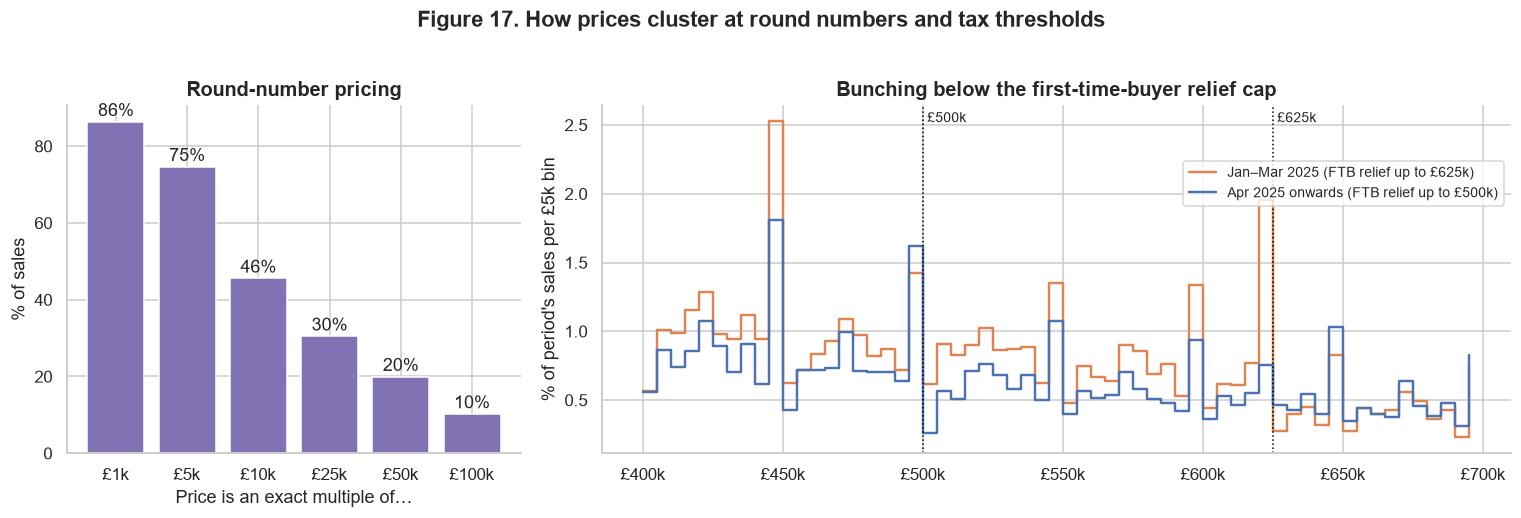

,threshold,period,sales £10k below,sales £10k above,below / above
0,"£500,000",Jan–Mar 2025,394,280,1.41
1,"£500,000",Apr 2025 onwards,826,303,2.73
2,"£625,000",Jan–Mar 2025,501,125,4.01
3,"£625,000",Apr 2025 onwards,477,324,1.47


In [20]:
p = df["price"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 2]})
mult = pd.Series({f"£{k//1000}k": (p % k == 0).mean() for k in [1000, 5000, 10000, 25000, 50000, 100000]})
axes[0].bar(mult.index, mult.values * 100, color="#8172B3")
for i, v in enumerate(mult.values):
    axes[0].text(i, v * 100 + 1.5, f"{v:.0%}", ha="center")
axes[0].set_ylabel("% of sales"); axes[0].set_xlabel("Price is an exact multiple of…")
axes[0].set_title("Round-number pricing")

post = df["date"] >= "2025-04-01"
bins = np.arange(400_000, 700_001, 5_000)
for mask, lab, col in [(~post, "Jan–Mar 2025 (FTB relief up to £625k)", "#DD8452"), (post, "Apr 2025 onwards (FTB relief up to £500k)", "#4C72B0")]:
    c, e = np.histogram(p[mask] - 1, bins=bins)   # -1 so a price of exactly £500,000 counts in the £495–500k bin
    axes[1].step(e[:-1], c / mask.sum() * 100, where="post", label=lab, color=col, lw=1.6)
for t in [500_000, 625_000]:
    axes[1].axvline(t, color="black", ls=":", lw=1)
    axes[1].text(t, 0.98, f" £{t//1000}k", fontsize=9, va="top", transform=axes[1].get_xaxis_transform())
axes[1].xaxis.set_major_formatter(gbp); axes[1].set_ylabel("% of period's sales per £5k bin")
axes[1].set_title("Bunching below the first-time-buyer relief cap"); axes[1].legend(fontsize=9, loc="upper right", bbox_to_anchor=(1, 0.86))
fig.suptitle("Figure 17. How prices cluster at round numbers and tax thresholds", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

rows = []
for t in [500_000, 625_000]:
    for lab, mask in [("Jan–Mar 2025", ~post), ("Apr 2025 onwards", post)]:
        below = ((p > t - 10_000) & (p <= t) & mask).sum(); above = ((p > t) & (p <= t + 10_000) & mask).sum()
        rows.append({"threshold": f"£{t:,}", "period": lab, "sales £10k below": below, "sales £10k above": above,
                     "below / above": round(below / above, 2)})
pd.DataFrame(rows)

**What it shows.** 75% of sales are agreed at an exact multiple of £5,000 and 20% at an exact multiple of £50,000. More striking, the location of the strongest bunching *moves* when the tax rules change. Before April 2025, first-time buyer relief applied to homes up to £625,000, and sales in the £10k just below £625k outnumbered those just above by **4.0 to 1**. From April the cap fell to £500,000: the ratio at £625k dropped to 1.5, while the ratio just below £500k rose from 1.4 to **2.7**, with a visible spike in the £495–500k bin and a hole immediately above it.

**Interpretation.** First-time buyer relief is a cliff edge: a buyer paying £1 over the cap loses the whole relief, which at £500k is worth £10,000. Buyers and sellers negotiate prices down to just under the threshold. This is a well-documented behaviour in UK housing research and a clear sign that agreed prices respond to tax design, not only to underlying value.

**Why it matters.**
- **Model errors will cluster at thresholds.** A home "worth" £510k may be recorded at £500k. Valuations within a few percent of a threshold are inherently uncertain, and a production AVM can flag them.
- **Policy analysis:** this is direct evidence that a stamp duty change shifted real transaction prices, useful for lenders and for anyone forecasting the impact of future tax changes.
- **Price is partly a negotiated, rounded number.** Even a perfect model cannot predict the last few thousand pounds, which sets a floor on achievable accuracy.

## 10. How much of price is location? The granularity ladder

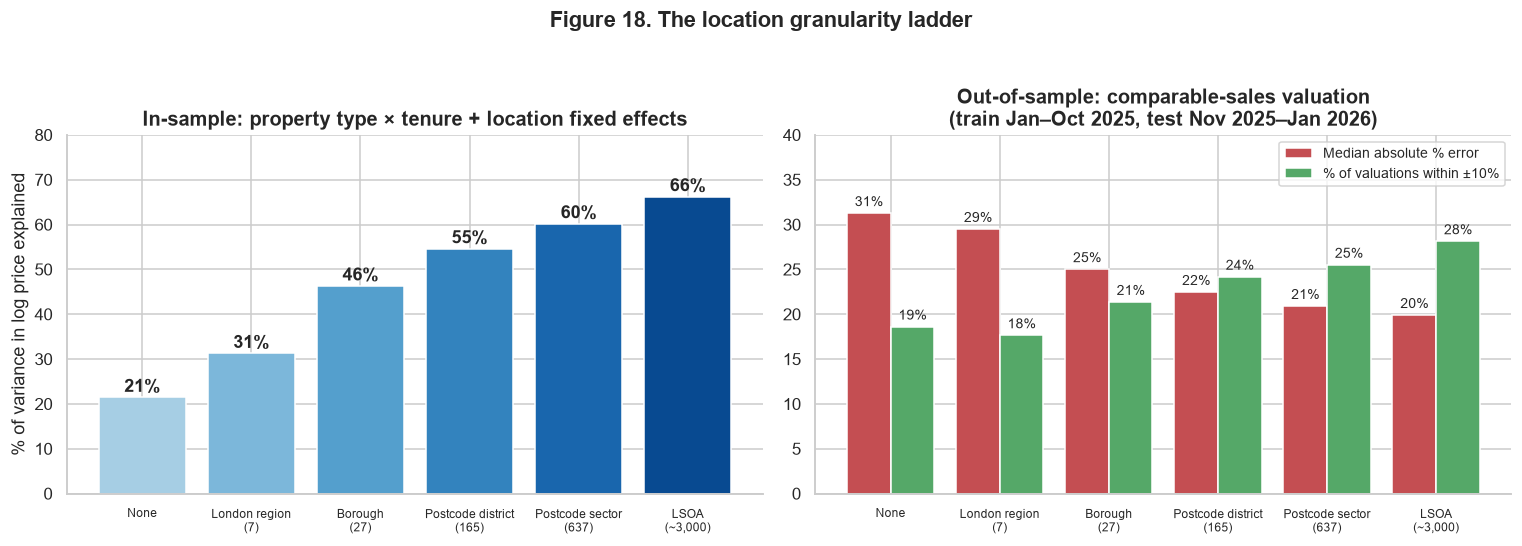

,MdAPE,Within ±10%,Within ±20%
None,31.3%,18.6%,34.2%
London region (7),29.5%,17.6%,35.5%
Borough (27),25.0%,21.3%,41.0%
Postcode district (165),22.5%,24.2%,45.4%
Postcode sector (637),20.9%,25.5%,48.4%
"LSOA (~3,000)",19.9%,28.1%,50.3%


In [21]:
levels = [("None", None), ("London region\n(7)", "london_part"), ("Borough\n(27)", "borough"),
          ("Postcode district\n(165)", "pc_district"), ("Postcode sector\n(637)", "pc_sector"), ("LSOA\n(~3,000)", "lsoa_code")]
r2 = pd.Series({lab: fe_r2(df, "tt", grp) for lab, grp in levels})

train, test = df[df["date"] < "2025-11-01"], df[df["date"] >= "2025-11-01"]
chains = {"None": [None], "London region\n(7)": ["london_part", None], "Borough\n(27)": ["borough", None],
          "Postcode district\n(165)": ["pc_district", "borough", None],
          "Postcode sector\n(637)": ["pc_sector", "pc_district", "borough", None],
          "LSOA\n(~3,000)": ["lsoa_code", "pc_sector", "pc_district", "borough", None]}
oos = pd.DataFrame({lab: accuracy(test["log_price"], comps_avm(train, test, ch)) for lab, ch in chains.items()}).T

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(range(len(r2)), r2.values * 100, color=plt.cm.Blues(np.linspace(0.35, 0.9, len(r2))))
for i, v in enumerate(r2.values):
    axes[0].text(i, v * 100 + 1.2, f"{v:.0%}", ha="center", fontweight="bold")
axes[0].set_xticks(range(len(r2))); axes[0].set_xticklabels(r2.index, fontsize=8)
axes[0].set_ylabel("% of variance in log price explained"); axes[0].set_ylim(0, 80)
axes[0].set_title("In-sample: property type × tenure + location fixed effects")
x = np.arange(len(oos))
axes[1].bar(x - 0.2, oos["MdAPE"] * 100, 0.4, label="Median absolute % error", color="#C44E52")
axes[1].bar(x + 0.2, oos["Within ±10%"] * 100, 0.4, label="% of valuations within ±10%", color="#55A868")
for i, (a, b) in enumerate(zip(oos["MdAPE"], oos["Within ±10%"])):
    axes[1].text(i - 0.2, a * 100 + 0.8, f"{a:.0%}", ha="center", fontsize=9)
    axes[1].text(i + 0.2, b * 100 + 0.8, f"{b:.0%}", ha="center", fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels(oos.index, fontsize=8); axes[1].set_ylim(0, 40)
axes[1].set_title("Out-of-sample: comparable-sales valuation\n(train Jan–Oct 2025, test Nov 2025–Jan 2026)")
axes[1].legend(fontsize=9, loc="upper right")
fig.suptitle("Figure 18. The location granularity ladder", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()
oos.style.format("{:.1%}")

**What it shows.** Property type and tenure alone explain 21% of the variation in log price. Adding location step by step raises this to 31% (seven broad regions), 46% (borough), 55% (postcode district), 60% (sector) and 66% (LSOA). The right-hand panel tests the same idea honestly, on sales the method has not seen: valuing each home at the median price of the same property type in its area. Median error falls from 31% with no location to 20% at LSOA level, and the share of valuations within ±10% rises from 19% to 28%.

**Interpretation.** Location is worth roughly as much as all other available information combined, and finer location keeps helping down to the LSOA (about 1,500 residents). Going finer still, to individual postcodes, adds nothing out of sample: most postcodes have only one or two sales, too few to form a reliable comparable.

**Why it matters.**
- **This is the baseline any model must beat.** A comparable-sales rule with no machine learning achieves a 20% median error and 28% of valuations within ±10%. A gradient-boosted model is only worth deploying if it clearly improves on this, and results should always be presented against such a baseline.
- **Feature design:** location should enter the model at several levels at once (borough, district, sector, LSOA, coordinates), with fallback to coarser levels when local data is thin. This mirrors how professional valuers widen their search radius when there are few nearby comparables.
- **Remaining gap:** the 20% error that location and type cannot explain is mostly *size* and *condition*. That is the quantified case for adding floor area from EPC data.

## 11. Spatial structure in what the model misses

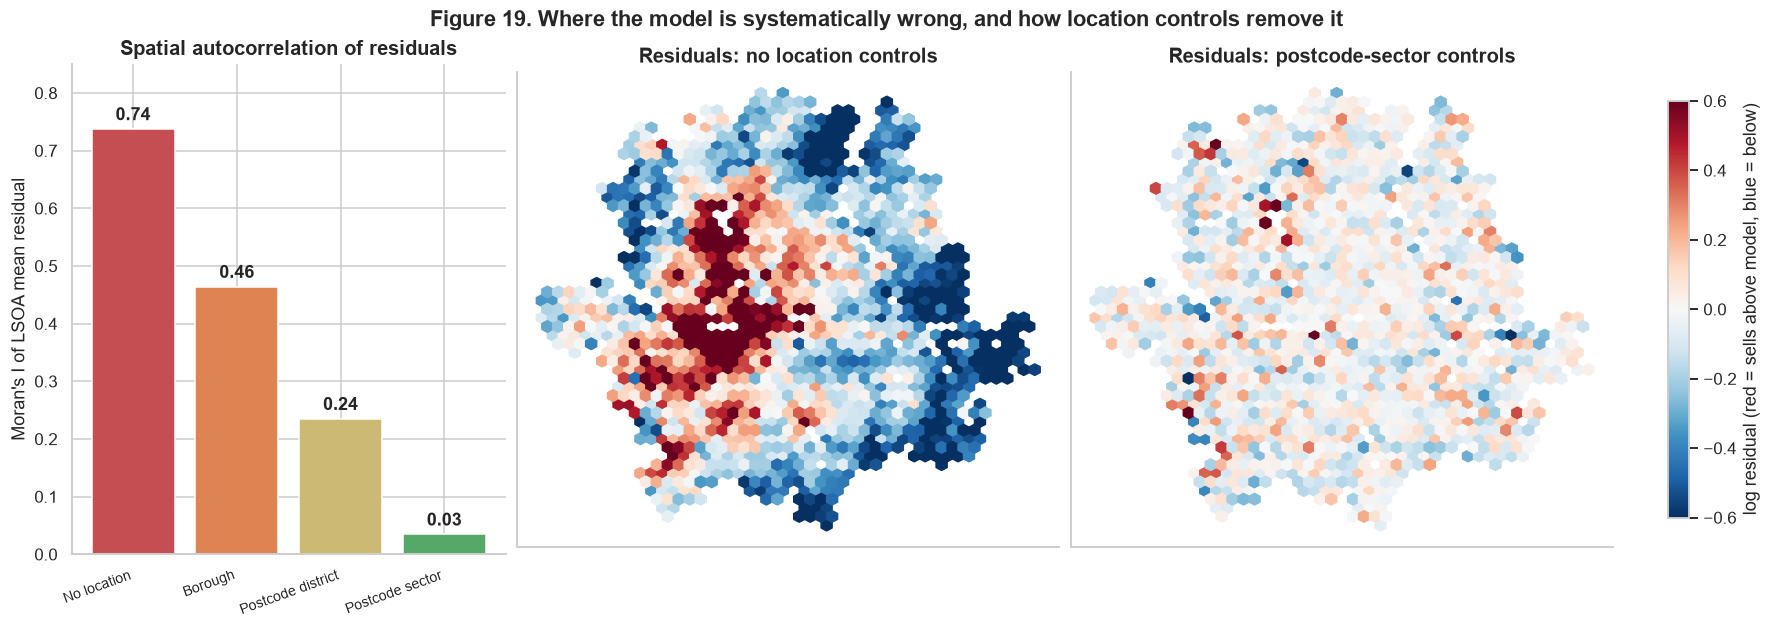

No location          0.738
Borough              0.464
Postcode district    0.235
Postcode sector      0.035
dtype: float64

In [22]:
spec = (["tt", "nb", "street_sfx", "mon"], {"tt": "Flat · leasehold", "nb": "Existing", "street_sfx": "Road", "mon": "2025-01"})
df["_all"] = "London"
res = {}
for lab, grp in [("No location", "_all"), ("Borough", "borough"), ("Postcode district", "pc_district"), ("Postcode sector", "pc_sector")]:
    res[lab] = hedonic(df, *spec, grp)[2]
mi = {}
for lab, r in res.items():
    g = df.assign(r=r).groupby("lsoa_code").agg(r=("r", "mean"), lat=("latitude", "mean"), lon=("longitude", "mean"), n=("r", "size"))
    g = g[g["n"] >= 5]
    mi[lab] = morans_i(g["r"].values, g["lat"].values, g["lon"].values)
mi = pd.Series(mi)

fig = plt.figure(figsize=(16, 5.6), layout="constrained")
gs = fig.add_gridspec(1, 3, width_ratios=[0.8, 1, 1])
ax0 = fig.add_subplot(gs[0])
ax0.bar(range(len(mi)), mi.values, color=["#C44E52", "#DD8452", "#CCB974", "#55A868"])
for i, v in enumerate(mi.values):
    ax0.text(i, v + 0.015, f"{v:.2f}", ha="center", fontweight="bold")
ax0.set_xticks(range(len(mi))); ax0.set_xticklabels(mi.index, rotation=20, ha="right", fontsize=9)
ax0.set_ylabel("Moran's I of LSOA mean residual"); ax0.set_ylim(0, 0.85)
ax0.set_title("Spatial autocorrelation of residuals")
for j, lab in enumerate(["No location", "Postcode sector"]):
    ax = fig.add_subplot(gs[j + 1])
    hb = ax.hexbin(df["longitude"], df["latitude"], C=res[lab], reduce_C_function=np.mean, gridsize=45,
                   cmap="RdBu_r", vmin=-0.6, vmax=0.6, mincnt=3)
    ax.set_aspect(1 / np.cos(np.radians(51.5))); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title({"No location": "Residuals: no location controls", "Postcode sector": "Residuals: postcode-sector controls"}[lab])
cb = fig.colorbar(hb, ax=fig.axes[1:], shrink=0.85)
cb.set_label("log residual (red = sells above model, blue = below)")
fig.suptitle("Figure 19. Where the model is systematically wrong, and how location controls remove it", fontweight="bold")
plt.show()
mi.round(3)

**What it shows.** We fit a model of log price on property type, tenure, new-build status, street suffix and month, and look at what it gets wrong. With no location information, errors are strongly clustered in space: Moran's I is **0.74** (0 means no spatial pattern, 1 means perfectly clustered), and the residual map shows the west and centre in red (selling above the model) and the east in blue. Adding borough controls cuts Moran's I to 0.46, postcode district to 0.24, and postcode sector to **0.03**, effectively removing the spatial pattern. The right-hand map is close to uniform.

**Interpretation.** Neighbouring homes share unobserved advantages: schools, transport, green space, reputation. Any model that leaves these out makes errors that are *correlated across neighbours*, so whole areas are systematically over- or under-valued.

**Why it matters.**
- **For lenders this is a concentration risk.** Systematic over-valuation of one area means a lender's collateral is overstated across many loans at once. Testing residuals for spatial autocorrelation is a standard check in AVM validation for this reason.
- **For model validation:** random train/test splits can understate error when neighbouring homes leak information into each other. Spatial or time-based splits are more honest.
- **Practical rule:** check Moran's I on the final model's residuals. If it is materially above zero, the model is still missing location information.

## 12. What is each characteristic worth? Hedonic regression

R² (with postcode-sector fixed effects): 0.619


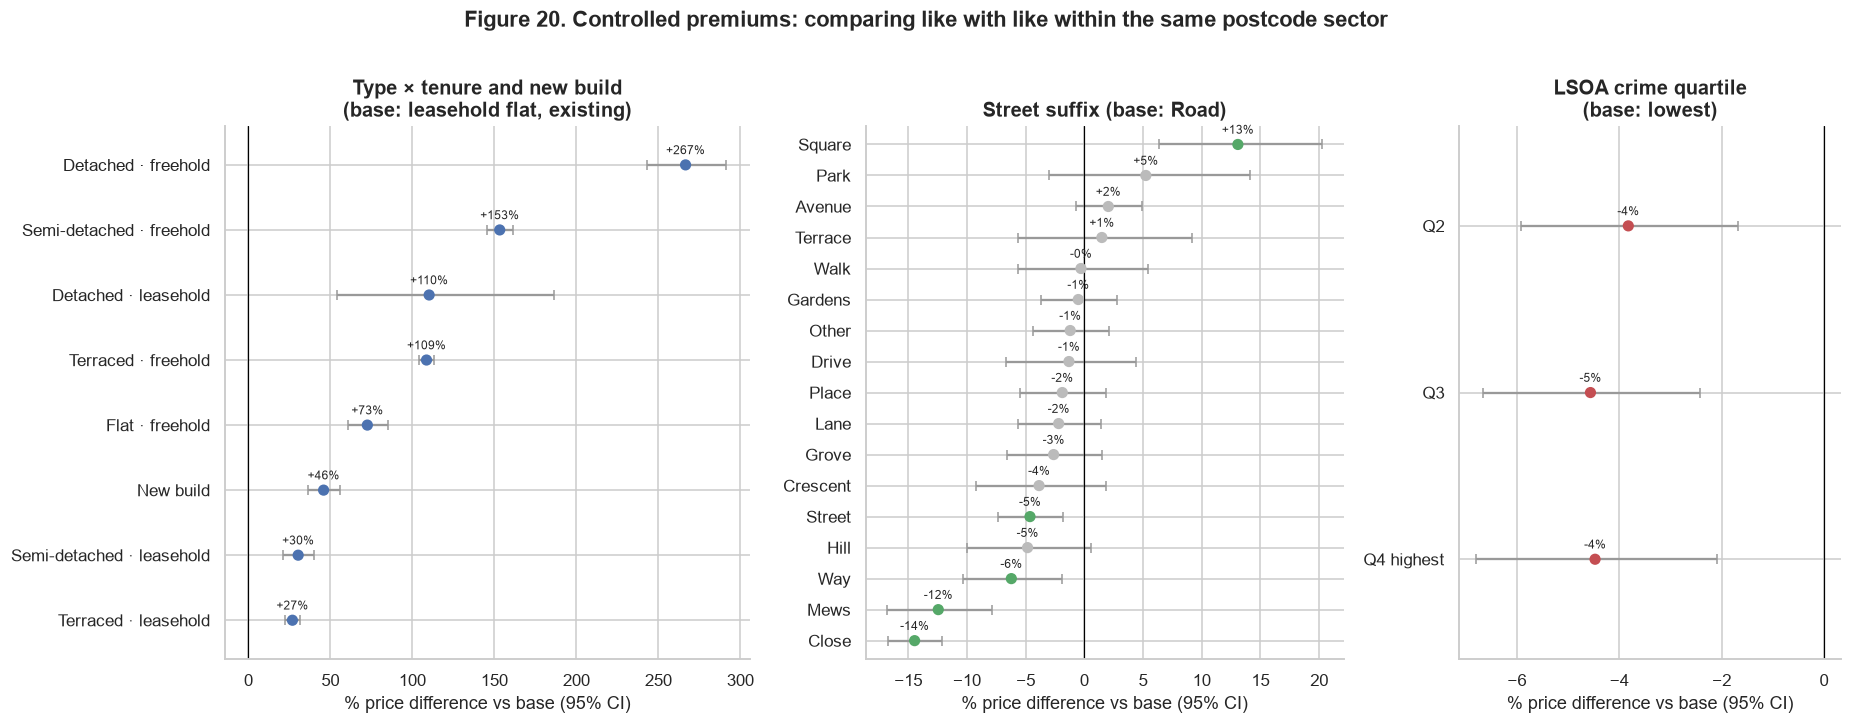

In [23]:
base_all = {"tt": "Flat · leasehold", "nb": "Existing", "street_sfx": "Road", "mon": "2025-01", "cq": "Q1 lowest"}
H, r2_all, resid_all = hedonic(df, ["tt", "nb", "street_sfx", "mon", "cq"], base_all, "pc_sector")
print(f"R² (with postcode-sector fixed effects): {r2_all:.3f}")

def forest(ax, t, title, color="#4C72B0", order=None):
    t = t.loc[order[::-1]] if order is not None else t.sort_values("pct")
    y = np.arange(len(t))
    sig = (t["lo"] > 0) | (t["hi"] < 0)
    ax.errorbar(t["pct"] * 100, y, xerr=[(t["pct"] - t["lo"]) * 100, (t["hi"] - t["pct"]) * 100],
                fmt="none", ecolor="#999999", capsize=3)
    ax.scatter(t["pct"] * 100, y, color=np.where(sig, color, "#BBBBBB"), zorder=3, s=40)
    for yi, v in zip(y, t["pct"]):
        ax.annotate(f"{v:+.0%}", (v * 100, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
    ax.set_ylim(-0.6, len(t) - 0.4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(y); ax.set_yticklabels([i.split("=", 1)[1] for i in t.index])
    ax.set_xlabel("% price difference vs base (95% CI)"); ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.1, 1, 0.8]})
forest(axes[0], H[H.index.str.startswith(("tt=", "nb="))], "Type × tenure and new build\n(base: leasehold flat, existing)")
forest(axes[1], H[H.index.str.startswith("street_sfx=")], "Street suffix (base: Road)", "#55A868")
forest(axes[2], H[H.index.str.startswith("cq=")], "LSOA crime quartile\n(base: lowest)", "#C44E52",
       order=["cq=Q2", "cq=Q3", "cq=Q4 highest"])
fig.suptitle("Figure 20. Controlled premiums: comparing like with like within the same postcode sector",
             fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Method.** A *hedonic regression* is the standard industry and academic tool for pricing characteristics: it regresses log price on property features while holding location constant. Here every sale is compared only with other sales in the **same postcode sector** (637 "fixed effects"), so each bar answers: *within the same few streets, how much more or less does a home with this characteristic sell for?* Grey points are not statistically different from zero. Standard errors are clustered by sector.

**What it shows.**
- **Type and tenure:** within the same sector, a freehold terraced house sells for about twice a leasehold flat, and a freehold detached house over three times. Leasehold houses sell far below freehold equivalents.
- **New build: about +46%** versus existing homes of the same type in the same sector. This is larger than the raw comparison, because new builds are concentrated in cheaper eastern areas (Section 15). Some of it is real (modern specification, energy efficiency) and some is unmeasured size and developer pricing, so treat it as an upper bound.
- **Street suffix changes meaning once location is controlled.** In the raw data "Mews" was the most expensive suffix (Figure 13). Within the same sector, Mews homes sell about **12% below** homes on the main roads. Mews houses are typically small converted stables behind grand streets, so the raw premium was entirely location. "Square" keeps a genuine premium of about +13%; "Close" stays about 15% below.
- **Crime:** within the same postcode sector, homes in the highest-crime LSOA quartile sell about **4–5% less** than those in the lowest. Most of the crime effect seen in Figure 15 operates between areas, not within them.

Flats model R²: 0.468


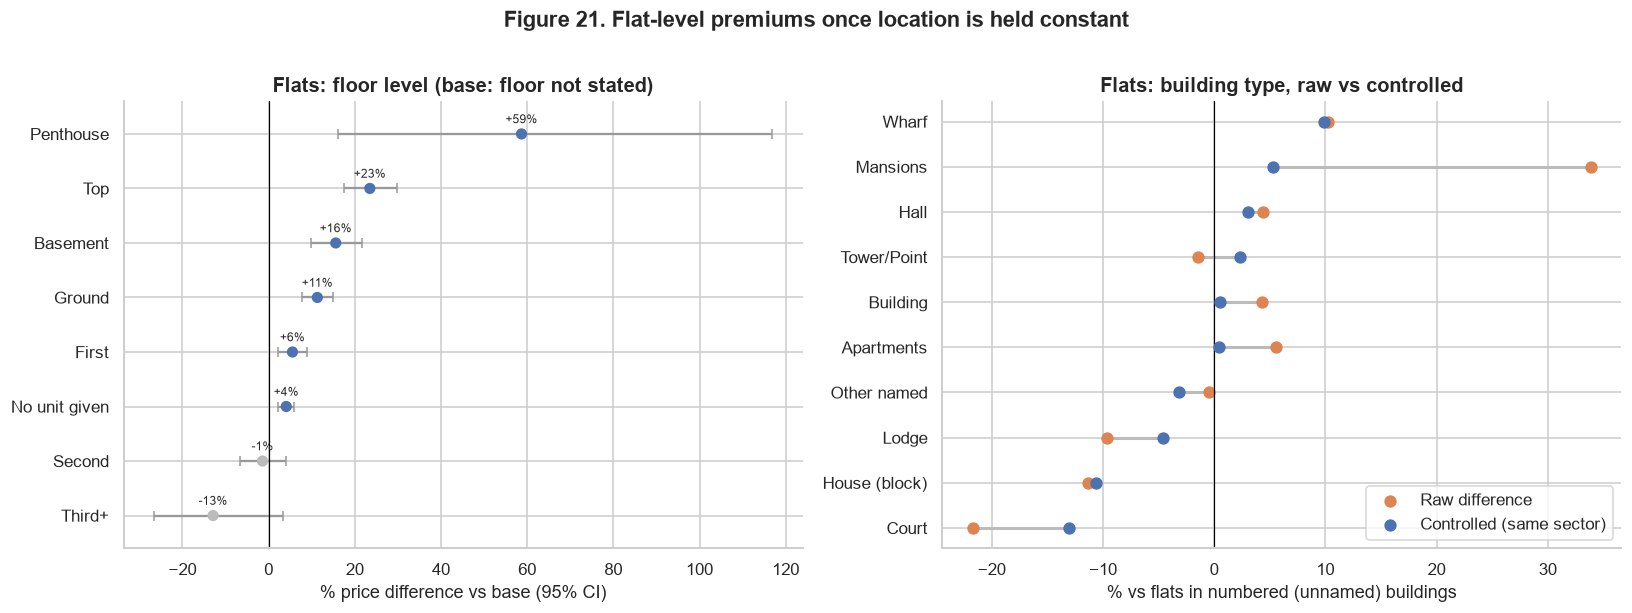

,Raw difference,Controlled (same sector)
Court,-21.7%,-13.0%
House (block),-11.3%,-10.7%
Lodge,-9.6%,-4.6%
Other named,-0.5%,-3.2%
Apartments,+5.5%,+0.5%
Building,+4.3%,+0.5%
Tower/Point,-1.5%,+2.3%
Hall,+4.4%,+3.0%
Mansions,+33.8%,+5.3%
Wharf,+10.2%,+9.9%


In [24]:
fl = df[df["property_type"] == "F"].copy()
fl["fl"] = fl["floor_level"].replace({"Whole property": "No unit given"})
base_fl = {"fl": "Not stated", "building_type": "Numbered only", "nb": "Existing", "street_sfx": "Road", "mon": "2025-01", "cq": "Q1 lowest"}
HF, r2_fl, _ = hedonic(fl, ["fl", "building_type", "nb", "street_sfx", "mon", "cq"], base_fl, "pc_sector")
print(f"Flats model R²: {r2_fl:.3f}")

raw_bt = fl.groupby("building_type")["log_price"].mean()
raw_bt = np.exp(raw_bt - raw_bt["Numbered only"]) - 1
ctrl = HF[HF.index.str.startswith("building_type=")]["pct"]
ctrl.index = ctrl.index.str.split("=").str[1]
comp = pd.DataFrame({"Raw difference": raw_bt.drop("Numbered only"), "Controlled (same sector)": ctrl}).dropna()
comp = comp.loc[fl["building_type"].value_counts().loc[comp.index].pipe(lambda s: s[s >= 70]).index].sort_values("Controlled (same sector)")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
forest(axes[0], HF[HF.index.str.startswith("fl=")], "Flats: floor level (base: floor not stated)")
y = np.arange(len(comp))
for yi, (r, c) in enumerate(zip(comp["Raw difference"], comp["Controlled (same sector)"])):
    axes[1].plot([r * 100, c * 100], [yi, yi], color="#BBBBBB", lw=2, zorder=1)
axes[1].scatter(comp["Raw difference"] * 100, y, color="#DD8452", label="Raw difference", zorder=2, s=50)
axes[1].scatter(comp["Controlled (same sector)"] * 100, y, color="#4C72B0", label="Controlled (same sector)", zorder=3, s=50)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_yticks(y); axes[1].set_yticklabels(comp.index)
axes[1].set_xlabel("% vs flats in numbered (unnamed) buildings"); axes[1].legend(loc="lower right")
axes[1].set_title("Flats: building type, raw vs controlled")
fig.suptitle("Figure 21. Flat-level premiums once location is held constant", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()
comp.style.format("{:+.1%}")

**What it shows.**
- **Floor level:** top-floor flats sell about **+23%** and penthouses roughly **+59%** (with a wide interval, as there are only 19) relative to flats whose address gives no floor. Ground and basement flats also show premiums (+11% and +16%) within the same sector, plausibly because "Ground Floor Flat" or "Basement Flat" addresses usually mean a flat with its own entrance and garden in a converted period house.
- **Building type, raw versus controlled:** the "Mansions" premium shrinks from about +34% raw to about +5% (not significant) within the same sector. Mansion blocks are expensive mainly because of *where* they are. In contrast, "Court" and "House" blocks stay around **10–13% cheaper** even against flats on the same streets, which is consistent with their typical post-war or former council construction.

**Why it matters.** The gap between orange and blue dots is the size of the location confounding. Business stakeholders often ask "what is a characteristic worth?". The honest answer is the controlled figure, and this chart shows why a raw average can overstate a premium more than sixfold.

## 13. A mix-adjusted price index

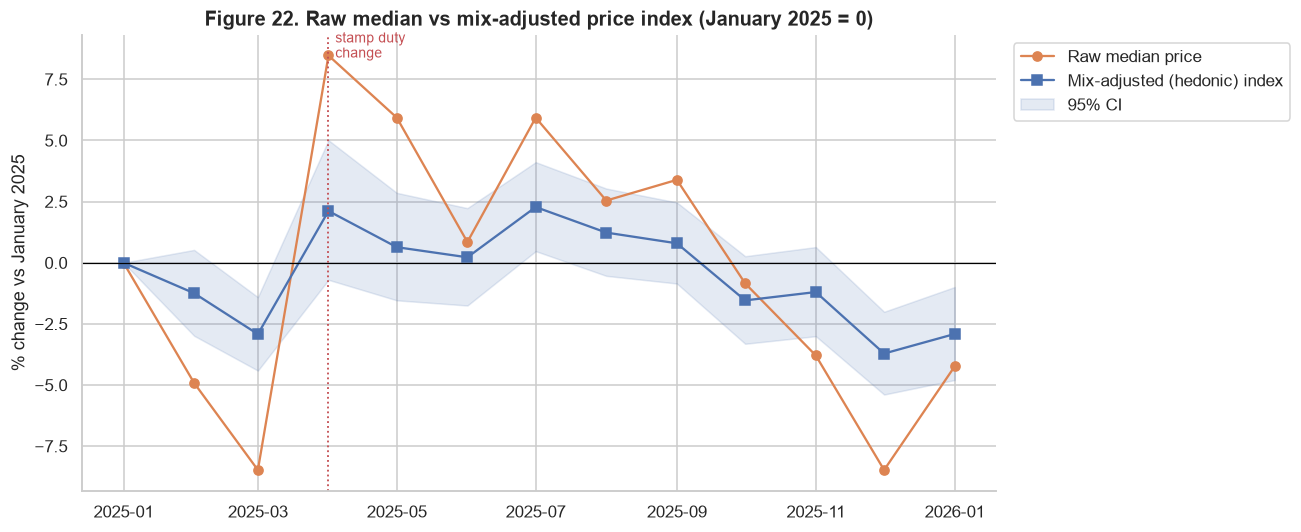

,Raw median,Mix-adjusted
2025-01-01 00:00:00,+0.0%,+0.0%
2025-02-01 00:00:00,-4.9%,-1.2%
2025-03-01 00:00:00,-8.5%,-2.9%
2025-04-01 00:00:00,+8.5%,+2.1%
2025-05-01 00:00:00,+5.9%,+0.6%
2025-06-01 00:00:00,+0.8%,+0.2%
2025-07-01 00:00:00,+5.9%,+2.3%
2025-08-01 00:00:00,+2.5%,+1.2%
2025-09-01 00:00:00,+3.4%,+0.8%
2025-10-01 00:00:00,-0.8%,-1.5%


In [25]:
idx = H[H.index.str.startswith("mon=")].copy()
idx.index = pd.PeriodIndex(idx.index.str.split("=").str[1], freq="M").to_timestamp()
idx.loc[pd.Timestamp("2025-01-01")] = [0, 0, 0]; idx = idx.sort_index()
raw_med = df.groupby("month")["price"].median(); raw_med.index = raw_med.index.to_timestamp()
raw_idx = raw_med / raw_med.iloc[0] - 1

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(raw_idx.index, raw_idx * 100, marker="o", color="#DD8452", label="Raw median price")
ax.plot(idx.index, idx["pct"] * 100, marker="s", color="#4C72B0", label="Mix-adjusted (hedonic) index")
ax.fill_between(idx.index, idx["lo"] * 100, idx["hi"] * 100, color="#4C72B0", alpha=0.15, label="95% CI")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(pd.Timestamp("2025-04-01"), color="#C44E52", ls=":", lw=1.2)
ax.text(pd.Timestamp("2025-04-04"), ax.get_ylim()[1] * 0.9, "stamp duty\nchange", color="#C44E52", fontsize=9)
ax.set_ylabel("% change vs January 2025"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Figure 22. Raw median vs mix-adjusted price index (January 2025 = 0)")
plt.tight_layout(); plt.show()
pd.DataFrame({"Raw median": raw_idx, "Mix-adjusted": idx["pct"]}).style.format("{:+.1%}")

**What it shows.** The raw median swings from **−8.5%** in March to **+8.5%** in April, a 17-point move in a single month. The mix-adjusted index, which compares like-for-like homes in the same postcode sector, moves from **−2.9%** to **+2.1%**. Over the full period, the mix-adjusted index drifts gently and ends about 3% below January, a much calmer and more credible picture of a flat-to-softening London market.

**Interpretation.** Most of the raw swing was composition: which homes happened to sell, not what homes were worth. A small genuine March dip remains, consistent with sellers accepting slightly lower prices to complete before the tax deadline.

**Why it matters.** This is exactly why the official UK House Price Index uses a hedonic, mix-adjusted method rather than raw medians. For a lender or investor, tracking the raw median would have suggested a crash and a boom within two months. The mix-adjusted series is also what the valuation model should use to bring older sales up to today's values ("time-adjusting comparables").

## 14. Predictability: where valuations are hardest

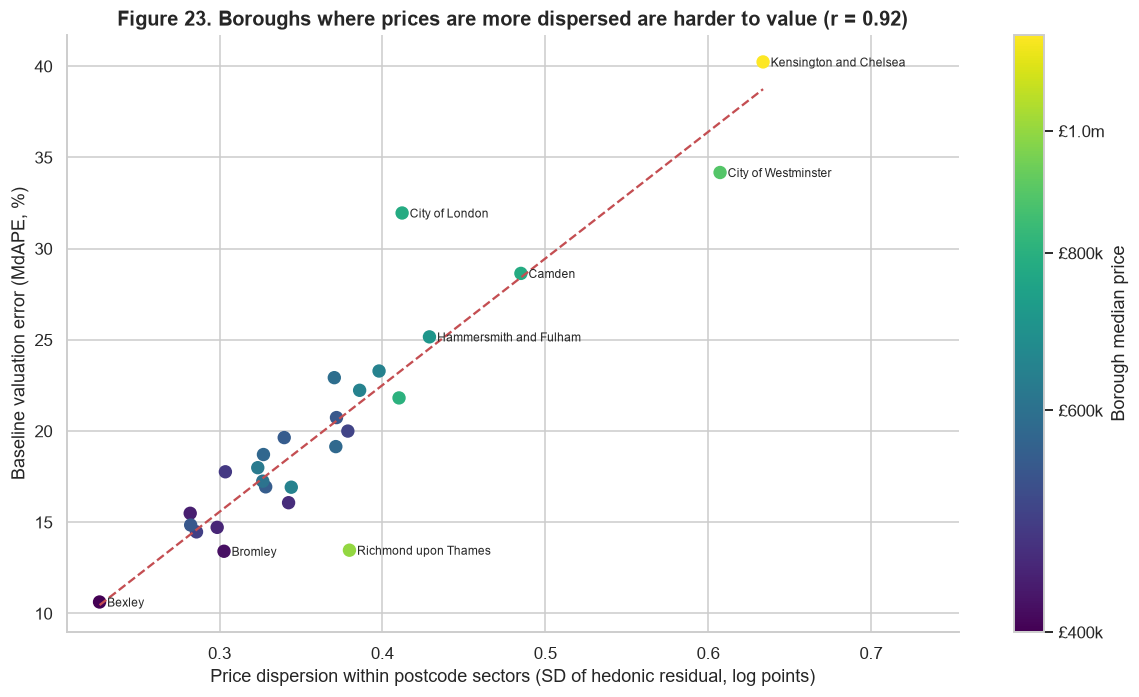

In [26]:
p_test = comps_avm(train, test, ["lsoa_code", "pc_sector", "pc_district", "borough", None])
test = test.assign(ape=np.abs(np.exp(p_test - test["log_price"]) - 1), pred_price=np.exp(p_test))
by_b = pd.DataFrame({"MdAPE": test.groupby("borough")["ape"].median(),
                     "dispersion": df.assign(r=resid_all).groupby("borough")["r"].std(),
                     "median_price": df.groupby("borough")["price"].median()}).dropna()
r = np.corrcoef(by_b["dispersion"], by_b["MdAPE"])[0, 1]

fig, ax = plt.subplots(figsize=(11, 6.5))
sc = ax.scatter(by_b["dispersion"], by_b["MdAPE"] * 100, s=60, c=np.log10(by_b["median_price"]), cmap="viridis")
label = by_b[(by_b["MdAPE"] > 0.24) | (by_b["MdAPE"] < 0.14)].index
for name, row in by_b.loc[label].iterrows():
    ax.annotate(name, (row["dispersion"], row["MdAPE"] * 100), xytext=(5, -3), textcoords="offset points", fontsize=8)
ax.set_xlim(by_b["dispersion"].min() - 0.02, by_b["dispersion"].max() + 0.12)
z = np.polyfit(by_b["dispersion"], by_b["MdAPE"] * 100, 1)
xs = np.linspace(by_b["dispersion"].min(), by_b["dispersion"].max(), 50)
ax.plot(xs, np.polyval(z, xs), ls="--", color="#C44E52")
cb = fig.colorbar(sc, ax=ax); cb.set_label("Borough median price")
cb.set_ticks(np.log10([4e5, 6e5, 8e5, 1e6])); cb.set_ticklabels(["£400k", "£600k", "£800k", "£1.0m"])
ax.set_xlabel("Price dispersion within postcode sectors (SD of hedonic residual, log points)")
ax.set_ylabel("Baseline valuation error (MdAPE, %)")
ax.set_title(f"Figure 23. Boroughs where prices are more dispersed are harder to value (r = {r:.2f})")
plt.tight_layout(); plt.show()

**What it shows.** Each point is a borough. The horizontal axis measures how much prices vary among otherwise similar homes in the same postcode sector; the vertical axis is the baseline valuation error. The two are almost perfectly aligned (**r = 0.92**). Outer and more uniform boroughs such as Bexley, Bromley and Enfield have errors of 11–15%. Prime central boroughs are hardest: Westminster 34%, Kensington and Chelsea 40%. Richmond is a useful exception: expensive, but its homes are relatively uniform within each sector, so its error (13%) is among the lowest.

**Interpretation.** In prime central London, homes on the same street differ enormously in size, condition, outlook and specification, none of which is in the data. In outer boroughs with uniform terraces and semis, the street is a good guide to the house.

**Why it matters.**
- **Confidence scoring.** Commercial AVMs return a *confidence level* with each valuation, and lenders only accept automated valuations above a confidence threshold, sending the rest to a surveyor. Local price dispersion is one of the best inputs to that score, and this chart is the evidence.
- **Segmented reporting.** A single London-wide accuracy number hides a near fourfold range between boroughs. Accuracy should always be reported by area and segment.

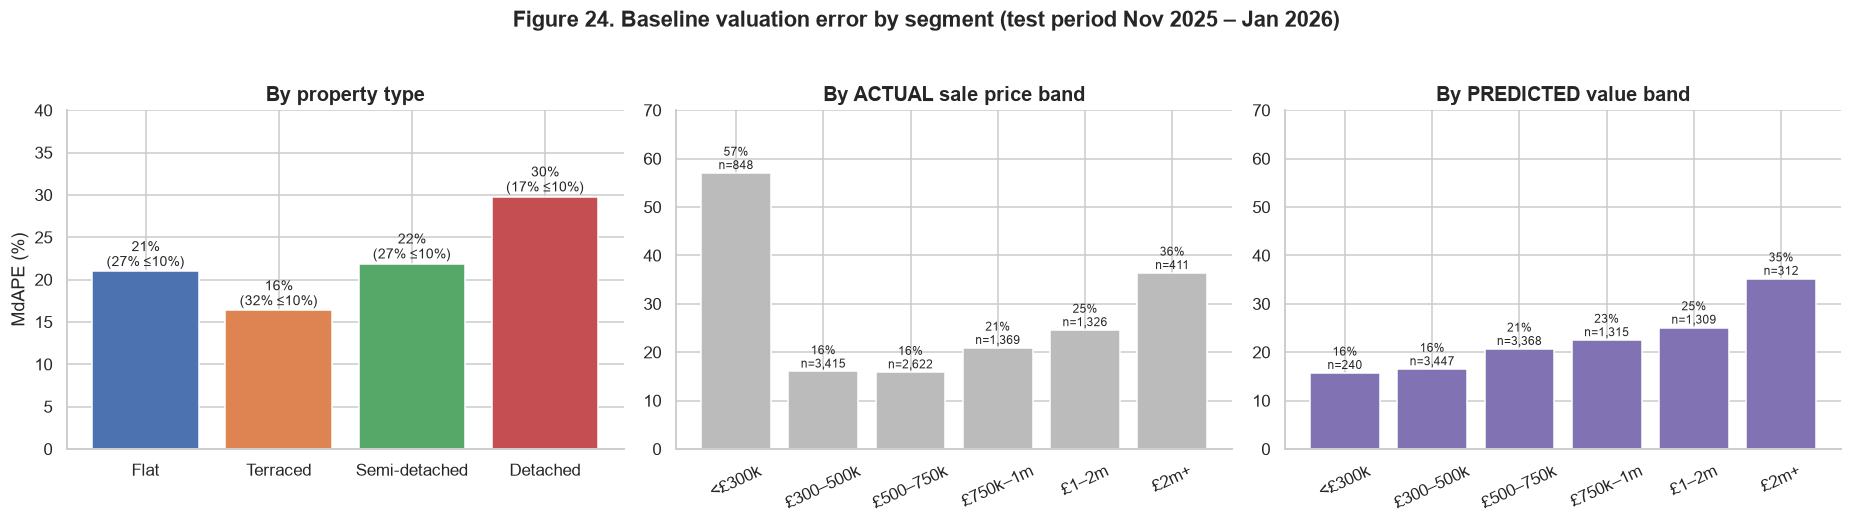

In [27]:
bands = [0, 300e3, 500e3, 750e3, 1e6, 2e6, np.inf]
blabels = ["<£300k", "£300–500k", "£500–750k", "£750k–1m", "£1–2m", "£2m+"]
test["actual_band"] = pd.cut(test["price"], bands, labels=blabels)
test["pred_band"] = pd.cut(test["pred_price"], bands, labels=blabels)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
seg = test.groupby("type_name")["ape"].agg(MdAPE="median", within10=lambda s: (s <= 0.10).mean()).reindex(TYPE_ORDER)
axes[0].bar(seg.index, seg["MdAPE"] * 100, color=[PALETTE[t] for t in seg.index])
for i, (a, b) in enumerate(zip(seg["MdAPE"], seg["within10"])):
    axes[0].text(i, a * 100 + 0.6, f"{a:.0%}\n({b:.0%} ≤10%)", ha="center", fontsize=9)
axes[0].set_ylim(0, 40); axes[0].set_ylabel("MdAPE (%)"); axes[0].set_title("By property type")
for ax, col, title in [(axes[1], "actual_band", "By ACTUAL sale price band"), (axes[2], "pred_band", "By PREDICTED value band")]:
    s = test.groupby(col, observed=True)["ape"].agg(MdAPE="median", n="size")
    ax.bar(s.index.astype(str), s["MdAPE"] * 100, color="#8172B3" if col == "pred_band" else "#BBBBBB")
    for i, (a, n) in enumerate(zip(s["MdAPE"], s["n"])):
        ax.text(i, a * 100 + 0.8, f"{a:.0%}\nn={n:,}", ha="center", fontsize=8)
    ax.set_ylim(0, 70); ax.set_title(title); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Figure 24. Baseline valuation error by segment (test period Nov 2025 – Jan 2026)", fontweight="bold", y=1.03)
plt.tight_layout(); plt.show()

**What it shows.** Terraced houses are the easiest to value (16% median error, 32% within ±10%), detached houses the hardest (30%). By **actual** sale price, error looks U-shaped and extreme at the bottom (57% for sales under £300k). By **predicted** value, the pattern is a smooth rise with value, from about 16% under £500k to 35% above £2m.

**Interpretation.** The two middle panels show a classic evaluation trap. Grouping by actual price selects sales that ended up unusually cheap or expensive, which are by construction the ones the model missed. That is regression to the mean, not a real weakness at the bottom of the market. At valuation time only the *predicted* value is known, so performance must be reported by predicted band. The honest conclusion is that error grows with value: expensive homes are more individual.

**Why it matters.** Lenders set AVM acceptance rules by predicted value and confidence band (for example, accept automated valuations only below a value cap). Reporting by actual price would produce the wrong rules. This distinction is a common question in model validation interviews.

## 15. Market structure: new-build supply and tax bands

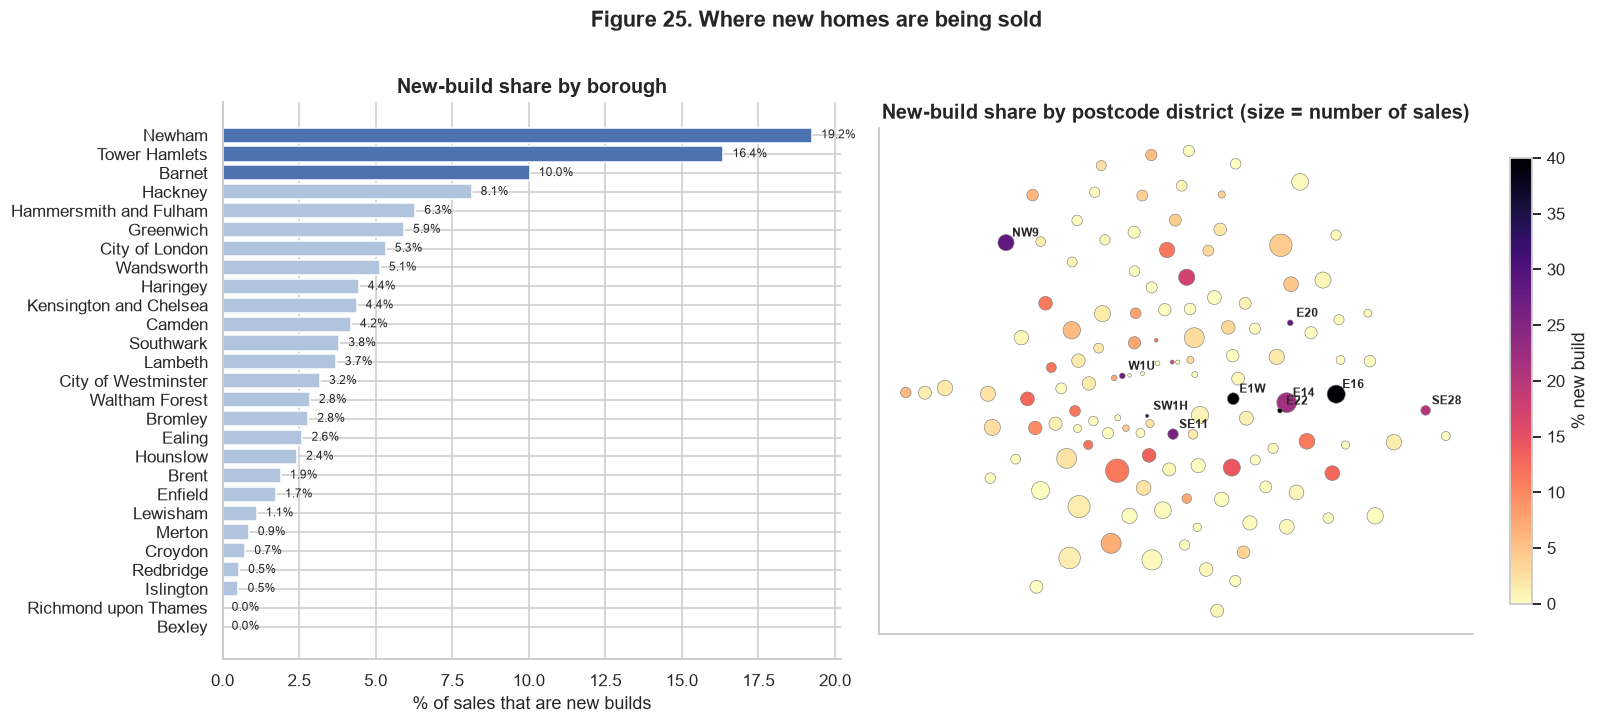

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.2]})
nbb = df.groupby("borough")["is_new_build"].mean().sort_values()
axes[0].barh(nbb.index, nbb.values * 100, color=["#4C72B0" if v > 0.1 else "#B0C4DE" for v in nbb.values])
for y, v in enumerate(nbb.values):
    axes[0].text(v * 100 + 0.3, y, f"{v:.1%}", va="center", fontsize=8)
axes[0].set_xlabel("% of sales that are new builds"); axes[0].set_title("New-build share by borough")
d = df.groupby("pc_district").agg(share=("is_new_build", "mean"), n=("price", "size"),
                                  lat=("latitude", "mean"), lon=("longitude", "mean"))
d = d[d["n"] >= 30]
sc = axes[1].scatter(d["lon"], d["lat"], s=d["n"] / 6, c=d["share"] * 100, cmap="magma_r", vmin=0, vmax=40,
                     edgecolor="grey", linewidth=0.4)
for name, row in d[d["share"] > 0.2].iterrows():
    axes[1].annotate(name, (row["lon"], row["lat"]), xytext=(4, 4), textcoords="offset points", fontsize=8, fontweight="bold")
axes[1].set_aspect(1 / np.cos(np.radians(51.5))); axes[1].set_xticks([]); axes[1].set_yticks([])
cb = fig.colorbar(sc, ax=axes[1], shrink=0.8); cb.set_label("% new build")
axes[1].set_title("New-build share by postcode district (size = number of sales)")
fig.suptitle("Figure 25. Where new homes are being sold", fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**What it shows.** New builds are 5.2% of sales overall, but they are highly concentrated: 19% of sales in Newham and 16% in Tower Hamlets, against close to zero in Richmond, Islington and Bexley. At district level the hotspots are the Docklands and Thames-side regeneration areas (E16 at 48%, E1W at 44%, E14 at 22%), the Olympic Park (E20), and Colindale in the north-west (NW9). 98.9% of new-build sales are flats.

**Why it matters.**
- **This is why the raw new-build comparison understated the premium** (Figure 5 vs Figure 20): new builds are sold mostly in cheaper eastern districts.
- **Concentration risk for lenders:** large single developments can dominate a district's sales, and new-build prices often fall on first resale once the developer premium disappears. Lenders typically limit loan-to-value or exposure per development for this reason.
- **Model monitoring:** areas with a high new-build share should have new-build valuations tracked separately, with a check on first resales once they occur.

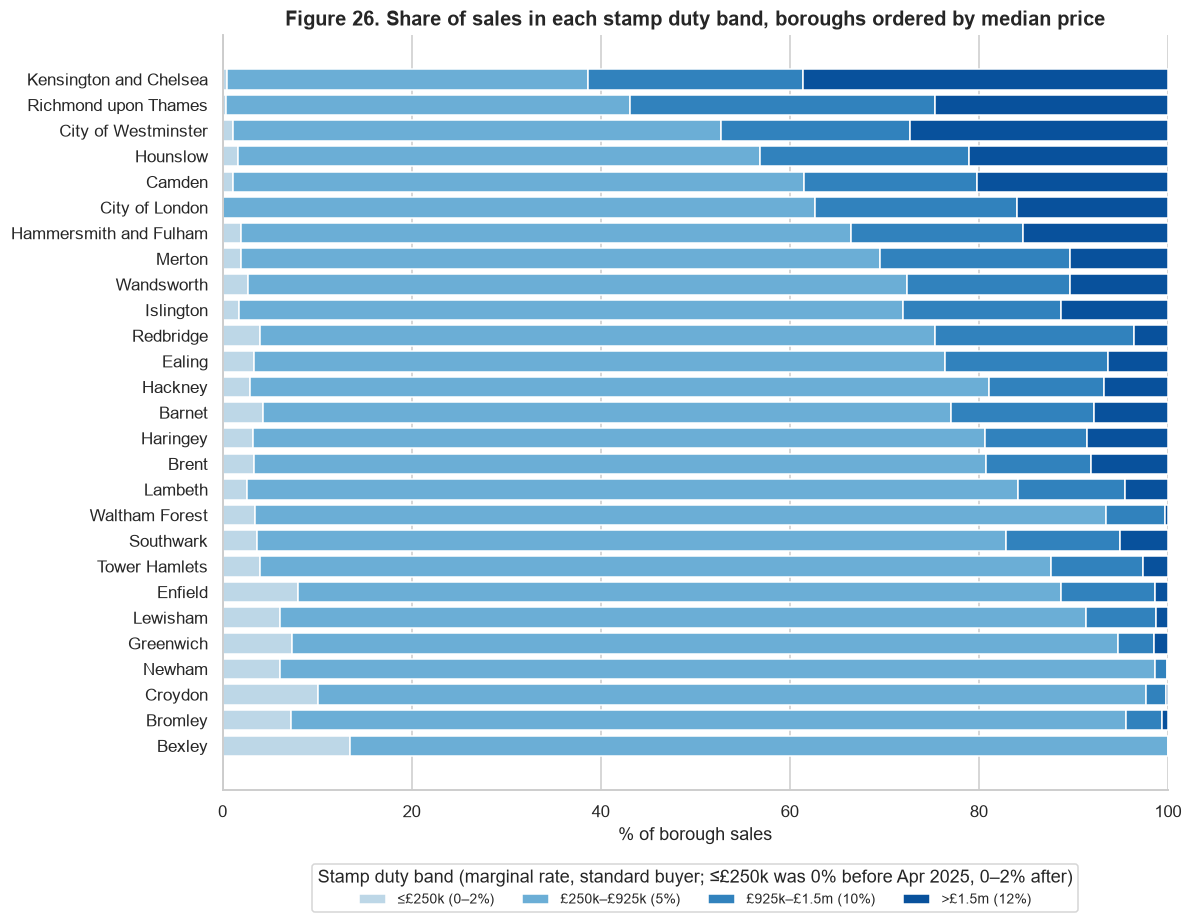

In [29]:
sdlt = pd.cut(df["price"], [0, 250e3, 925e3, 1.5e6, np.inf], labels=["≤£250k (0–2%)", "£250k–£925k (5%)", "£925k–£1.5m (10%)", ">£1.5m (12%)"])
ct = pd.crosstab(df["borough"], sdlt, normalize="index")
ct = ct.loc[df.groupby("borough")["price"].median().sort_values().index]
fig, ax = plt.subplots(figsize=(11, 8.5))
left = np.zeros(len(ct))
for col, c in zip(ct.columns, ["#BDD7E7", "#6BAED6", "#3182BD", "#08519C"]):
    ax.barh(ct.index, ct[col] * 100, left=left, color=c, label=col)
    left += ct[col].values * 100
ax.set_xlim(0, 100); ax.set_xlabel("% of borough sales")
ax.legend(title="Stamp duty band (marginal rate, standard buyer; ≤£250k was 0% before Apr 2025, 0–2% after)", loc="lower center", bbox_to_anchor=(0.5, -0.17), ncol=4, fontsize=9)
ax.set_title("Figure 26. Share of sales in each stamp duty band, boroughs ordered by median price")
plt.tight_layout(); plt.show()

**What it shows.** Across the sample, 75% of sales fall in the £250k–£925k band, where the marginal stamp duty rate for a standard buyer is 5%. In prime boroughs the picture changes: 39% of Kensington and Chelsea sales and 27% of Westminster sales are above £1.5m, where the 12% marginal rate applies. In the cheapest boroughs almost nothing exceeds £925k.

**Why it matters.** Tax changes hit boroughs very differently. A change to upper-band rates is a prime-central-London policy; a change to the nil-rate or first-time buyer thresholds (as in April 2025) mainly affects outer and eastern boroughs. Combined with the bunching evidence in Figure 17, this lets an analyst anticipate *where* volumes and prices will react to a future budget.

## 16. Outlier screening

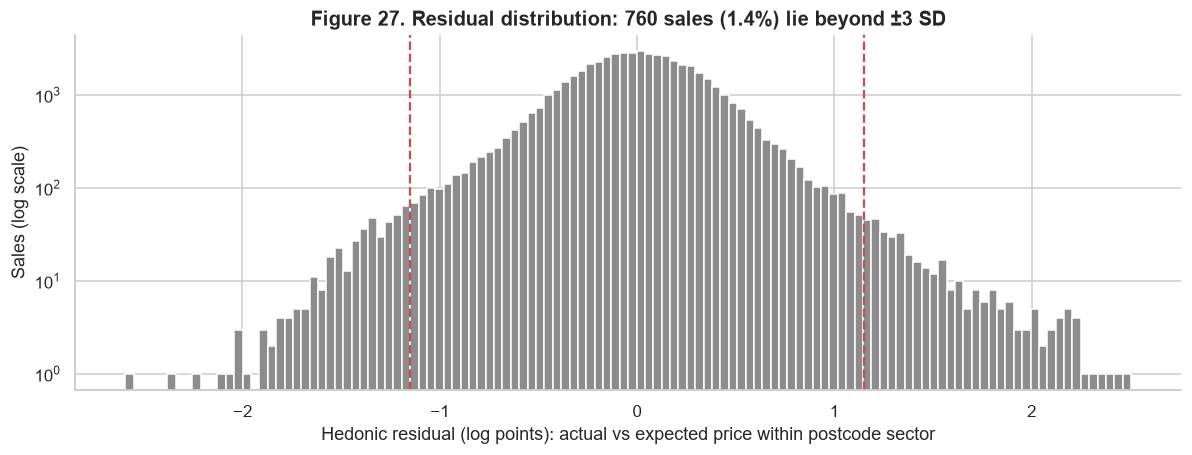

,price,type_name,borough,saon,paon,street,times_expected
55051,100000,Terraced,City of Westminster,NaN,26,MORETON PLACE,0.07
39174,72500,Terraced,Lewisham,LOWER FLOOR,77,QUEENSWOOD ROAD,0.09
63693,281000,Flat,City of Westminster,FLAT 4,20 - 21,MARYLEBONE HIGH STREET,0.11
55449,300000,Flat,Kensington and Chelsea,FLAT 4,28,CHESHAM PLACE,0.12
60124,136500,Flat,Wandsworth,30,"BILLINGTON MANSIONS, 29",SLEAFORD STREET,0.13
22139,400000,Detached,Camden,NaN,81,SWAINS LANE,0.13
57176,24500000,Terraced,Kensington and Chelsea,NaN,9,CHEYNE WALK,9.51
29613,53000000,Detached,Camden,NaN,87,AVENUE ROAD,10.02
47007,13200000,Flat,Wandsworth,APARTMENT 37,BOILER HOUSE BATTERSEA POWER STATION,CIRCUS ROAD SOUTH,10.50
63723,15150000,Flat,City of Westminster,FLAT 505,24,PADDINGTON STREET,11.18


In [30]:
sd = resid_all.std()
flag = resid_all.abs() > 3 * sd
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.hist(resid_all, bins=120, color="#8C8C8C", edgecolor="white")
for s in (-3, 3):
    ax.axvline(s * sd, color="#C44E52", ls="--")
ax.set_yscale("log"); ax.set_xlabel("Hedonic residual (log points): actual vs expected price within postcode sector")
ax.set_ylabel("Sales (log scale)")
ax.set_title(f"Figure 27. Residual distribution: {flag.sum():,} sales ({flag.mean():.1%}) lie beyond ±3 SD")
plt.tight_layout(); plt.show()
out = df.loc[flag, ["price", "type_name", "borough", "saon", "paon", "street"]].assign(
    times_expected=np.exp(resid_all[flag]).round(2)).sort_values("times_expected")
pd.concat([out.head(6), out.tail(6)])

**What it shows.** After controlling for type, tenure, new-build status, street suffix, month and postcode sector, 760 sales (1.4%) are more than three standard deviations from their expected price, and the distribution has much heavier tails than a normal distribution would. The extreme low cases include a terraced house in Westminster recorded at £100,000 and a Lewisham terrace at £72,500. The extreme high cases include flats recorded above £10m, such as a unit in the Battersea Power Station development.

**Interpretation.** Even after excluding category B, some category A records are not ordinary arm's-length sales of a single home: sales of partial interests or shares, sales between connected parties, lease arrangements, or several units bought in one transaction. Others are genuine but exceptional properties.

**Why it matters.** Industry practice is to screen training data with a model-based outlier filter like this one, because a small number of mis-recorded sales can bend a model's fit, particularly in thin local markets. Rather than deleting them silently, a common approach is to exclude flagged records from training, keep them in a review table, and report how many were removed, as in the funnel in Figure 1.

## 17. Conclusions and modelling decisions

| Finding | Evidence | Modelling decision |
|---|---|---|
| Prices are highly right-skewed | Skewness 13.2 raw, 0.9 log | Train on log price; report accuracy in % terms (median APE, % within ±10%) |
| Property type and tenure dominate | Medians £490k (flat) to £1.55m (detached); leasehold houses ~30% cheaper | Include type, tenure and a type × tenure interaction |
| Location is non-linear and directional | West > east at equal distance; steep distance gradient | Use coordinates, rotated coordinates, distance, postcode district; prefer gradient-boosted trees |
| Stamp duty change distorted the market | March volume 2.4× January; mix shift to cheaper homes | Time-based train/test split; include a policy flag; evaluate by month |
| Address text holds building-quality signal | Mansions £700k vs Court £410k; Mews vs Close +75% | Keep building type, floor level and street suffix features |
| Crime effect depends on centrality | −16% to −28% outside 4 km; reversed inside 4 km | Let a tree model learn the interaction; consider crime rates and type mix |
| Uneven borough coverage | 134 to 5,320 sales per borough | Report accuracy by borough; attach confidence scores to valuations |
| Location detail keeps helping down to LSOA | Baseline error 31% → 20% from no location to LSOA | Encode location at several levels with fallback; benchmark every model against the comparable-sales baseline |
| Residuals are spatially clustered without fine location | Moran's I 0.74 → 0.03 with sector controls | Check Moran's I on final residuals; use time-based or spatial validation splits |
| Raw monthly medians are dominated by mix | −8.5% / +8.5% raw vs −2.9% / +2.1% mix-adjusted | Time-adjust comparables with a hedonic index, not raw medians |
| Prices bunch below tax thresholds | Below/above ratio at £500k rose from 1.4 to 2.7 after April 2025 | Flag valuations near thresholds as less certain |
| Error scales with local dispersion and value | r = 0.92; MdAPE 16% (<£500k predicted) to 35% (£2m+) | Report accuracy by predicted value band; build confidence scores from local dispersion |
| 1.4% of sales are extreme residual outliers | Partial interests, multi-unit or connected-party sales | Exclude from training via residual screening; keep a review log |

### Limitations
- **No floor area or bedroom count.** Size is the strongest single driver of value in industry AVMs. Without it, part of the price variation within a postcode cannot be explained. Address-level EPC matching would add it and is the main future improvement.
- **Coverage is London postal districts only,** with several outer boroughs thin or absent.
- **One year of data** spanning a tax change. Seasonal patterns and longer-run trends cannot be separated reliably.
- **Completion prices lag agreed prices** by roughly two to four months, so the data describes the market as it was at the time of agreement.
- **Crime counts are not rates** and include footfall-driven categories.